# RAGF-BERT v5 - one model, layer-level techniques (no ensemble)

**Colab:** `Runtime -> Change runtime type -> T4 GPU`, `Run all`, upload `sarcasm_balanced_9600_full.csv` when asked.

**Single `bert-base-uncased` model.** No ensemble. The notebook trains the *same* model with different **layer-level treatments** and compares them on the same split, over several seeds:

| Variant | What it does to the BERT layers |
|---|---|
| Full fine-tuning | plain baseline, no rationale loss |
| Attention supervision | paper-style: last-layer [CLS] attention is trained toward the human rationale (lambda = 1.0) |
| + LLRD | layer-wise learning-rate decay: lower layers move less than upper layers |
| + re-init top 2 | re-initialise the top 2 encoder layers (they are the most task-specific) |
| + weighted layer pooling | classify from a learned mix of the [CLS] vectors of the last 4 layers |
| + multi-sample dropout | 5 dropout masks on the classifier head, averaged |
| + gradual unfreezing | train top 4 layers first, then 8, then all |
| + static freeze 3 | bottom 3 layers frozen for the whole run |
| RAGF-BERT | attention supervision + dynamic gradient-guided layer freezing |
| COMBO | LLRD + re-init + weighted pooling + multi-sample dropout |

**Selection rule:** the best variant is chosen by mean **validation** macro-F1 only; the test set is read once for reporting. A paired t-test over seeds shows whether a variant really beats the attention-supervision baseline. Fixes from v4 are kept (rationale loaded from `hate_rationale_weights`, `paper_split`, clean 3/3 extra posts, span IOU-F1).

**Be aware:** none of these techniques is guaranteed to help. The notebook reports the result either way.

**v6 addition - full paper comparison.** Section 9b now prints **all eight paper metrics** (accuracy, macro-F1, AUROC, IOU-F1, token-F1, AUPRC, comprehensiveness, sufficiency) for the paper baseline, the paper's proposed method, and ours (baseline, attention supervision, gradual unfreezing, and the validation-selected variant), plus the difference to the paper and a chart. Set `PAPER_COMPARISON_ONLY = True` in section 9 to run only those three variants (faster; use 5 seeds). Files written: `final_vs_paper_all_metrics.csv`, `delta_vs_paper_proposed.csv`, `paper_vs_ours_all_metrics.png`.


## 0. Experimental protocol

The notebook first checks whether valid human token-level rationales are available.

- With gold rationales: run full fine-tuning, static freezing, adaptive classification, adaptive rationale, and dual-objective RAGF-BERT.
- Without gold rationales: run full fine-tuning, static freezing, and adaptive classification; skip rationale-supervised runs without crashing. Generate illustrative model-based token explanations, but do not claim rationale plausibility improvements.

All methods use the same train/validation/test split. Results are measured on the held-out test set. Published paper scores are shown separately as contextual references, not as a matched baseline.


In [19]:
# Google Colab dependency setup — compatible with the current Colab Hugging Face stack.
# IMPORTANT:
# - Do not upgrade pip/setuptools blindly.
# - Do not install the old datasets/accelerate pins; this notebook does not use them.
# - Keep Colab's preinstalled PyTorch/CUDA untouched.
#
# Colab's current Transformers 5.x stack requires:
#   huggingface-hub >=1.31,<3
#   tokenizers >=0.23.1,<0.24
# We pin a mutually compatible set and request wheels only (no Rust compilation).

!python -m pip install -q --only-binary=:all: \
    "setuptools<82" "jedi>=0.16" \
    "huggingface-hub>=1.31,<3" \
    "tokenizers>=0.23.1,<0.24" \
    "transformers==5.21.0" \
    scikit-learn pandas numpy matplotlib seaborn

# Verify versions and imports. Restart runtime if Colab asks you to.
import sys, torch, transformers, tokenizers, huggingface_hub
print("Python:", sys.version)
print("PyTorch:", torch.__version__)
print("Transformers:", transformers.__version__)
print("Tokenizers:", tokenizers.__version__)
print("Hugging Face Hub:", huggingface_hub.__version__)
print("CUDA available:", torch.cuda.is_available())


Python: 3.13.16 (main, Oct  1 2026, 15:40:24) [GCC 13.3.0]
PyTorch: 2.14.1+cu130
Transformers: 5.21.0
Tokenizers: 0.23.3
Hugging Face Hub: 1.33.0
CUDA available: True


In [20]:
import os, re, gc, json, math, random, glob, copy, warnings, hashlib, time
from dataclasses import dataclass
from typing import List, Dict, Optional, Tuple
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from transformers import AutoTokenizer, AutoModel, get_linear_schedule_with_warmup
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import label_binarize
from sklearn.metrics import (accuracy_score, f1_score, classification_report,
                             confusion_matrix, roc_auc_score, precision_recall_curve,
                             auc)
import matplotlib.pyplot as plt
import seaborn as sns

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", DEVICE)
if torch.cuda.is_available():
    print(torch.cuda.get_device_name(0), torch.cuda.get_device_properties(0).total_memory/1024**3, "GB")

Device: cuda
Tesla T4 14.56317138671875 GB


## 1. Configuration and Colab paths

The next cells look in `/content` and Google Drive. You can upload files when prompted, or mount Drive and set the paths below. The notebook accepts your sarcasm CSV without requiring HateXplain to be present.


In [21]:
# ---- Google Colab configuration ----
import os, glob

# Optional: mount Google Drive if your datasets are stored there.
USE_GOOGLE_DRIVE = False
if USE_GOOGLE_DRIVE:
    from google.colab import drive
    drive.mount("/content/drive")

# If your files are in Drive, put their exact paths here.
USER_CSV_PATH = ""       # e.g. "/content/drive/MyDrive/data/sarcasm_balanced_9600.csv"
HATEXPLAIN_PATHS = []    # e.g. ["/content/drive/MyDrive/HateXplain/train.json", ...]

# Model/training configuration
MODEL_NAME = "bert-base-uncased"
MAX_LENGTH = 128
BATCH_SIZE = 16
EPOCHS = 4
WARMUP_FRACTION = 0.10
LR = 3e-5
WEIGHT_DECAY = 0.01
DROPOUT = 0.1
SEED = 42
NUM_WORKERS = 2
GRAD_ACCUM_STEPS = 1
MAX_GRAD_NORM = 1.0

# Dynamic policy settings (tune only on validation, never test)
MONITOR_EVERY_STEPS = 100
MIN_WARMUP_STEPS = 100
EMA_BETA = 0.8
FREEZE_PATIENCE = 3
UNFREEZE_PATIENCE = 2
FREEZE_QUANTILE = 0.20
UNFREEZE_IMPORTANCE_MULTIPLIER = 1.5
MIN_TRAINABLE_ENCODER_LAYERS = 4
MAX_FROZEN_ENCODER_LAYERS = 8
RAGF_MODE = "both"   # "both", "classification", "rationale", "none"
STATIC_FREEZE_BOTTOM = 0  # 0, 3, or 6 for static baselines

LAMBDA_RATIONALE = 1.0      # v4: was 0.001 (too small to have any effect)
LABEL_SMOOTHING = 0.0
RATIONALE_COLUMNS_CANDIDATES = [
    "rationale", "rationales", "sarcasm_rationale",
    "hate_rationale", "explanation"
]
# ---- v4 additions ----
SARCASM_RATIONALE_WEIGHT = 0.5   # rationale target = hate weight + 0.5 x sarcasm mask (as in the paper's combined rationale)
USE_PAPER_SPLIT = True           # use the CSV's paper_split (train / validation / test)
EXTRA_AGREE = "3/3"              # keep only extra HateXplain posts with 3/3 annotator agreement (None = all)
EXTRA_PLATFORM = None            # "gab" = drop extra Twitter posts
GOLD_THR = 0.5                   # human rationale word = hate weight >= 0.5
TEXT_COL = "text"
LABEL_COL = "label"

OUTPUT_DIR = "/content/ragf_bert"
os.makedirs(OUTPUT_DIR, exist_ok=True)


In [22]:
def set_seed(seed=SEED):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

set_seed()

## 2. Load and inspect datasets

You need at least one compatible dataset. The user's CSV is sufficient to run the classification experiments. HateXplain is optional but recommended for human-rationale supervision.

The canonical target classes are `hate`, `offensive`, and `normal`. Label mapping must be reviewed. We do not infer a distinction that the source labels do not provide.


In [23]:
# Find or upload the user's CSV and optional HateXplain files.
from pathlib import Path

def find_named_file(name, roots=("/content", "/content/drive/MyDrive")):
    for root in roots:
        if os.path.isdir(root):
            hits = glob.glob(os.path.join(root, "**", name), recursive=True)
            if hits:
                return hits[0]
    return None

if not USER_CSV_PATH or not os.path.isfile(USER_CSV_PATH):
    USER_CSV_PATH = find_named_file("*sarcasm_balanced_9600*.csv")

if USER_CSV_PATH is None:
    print("Upload your sarcasm_balanced_9600.csv now. You may also select HateXplain JSON files in the same upload dialog.")
    from google.colab import files
    uploaded = files.upload()
    uploaded_paths = [os.path.join("/content", name) for name in uploaded.keys()]
    csv_hits = [p for p in uploaded_paths if p.lower().endswith(".csv") and "sarcasm" in os.path.basename(p).lower()]
    if not csv_hits:
        csv_hits = [p for p in uploaded_paths if p.lower().endswith(".csv")]
    if csv_hits:
        USER_CSV_PATH = csv_hits[0]
    HATEXPLAIN_PATHS = HATEXPLAIN_PATHS + [
        p for p in uploaded_paths if p.lower().endswith((".json", ".jsonl"))
    ]

print("User CSV path:", USER_CSV_PATH)
if USER_CSV_PATH and os.path.isfile(USER_CSV_PATH):
    user_raw = pd.read_csv(USER_CSV_PATH)
    print("User CSV shape:", user_raw.shape)
    print("Columns:", list(user_raw.columns))
    display(user_raw.head())
    for c in user_raw.columns:
        if user_raw[c].nunique(dropna=True) < 30:
            print(c, user_raw[c].value_counts(dropna=False).head(20).to_dict())
else:
    user_raw = None
    print("No user CSV found. Upload it or set USER_CSV_PATH in the configuration cell.")


Upload your sarcasm_balanced_9600.csv now. You may also select HateXplain JSON files in the same upload dialog.


Saving sarcasm_balanced_9600_full.csv to sarcasm_balanced_9600_full.csv
User CSV path: /content/sarcasm_balanced_9600_full.csv
User CSV shape: (9600, 18)
Columns: ['post_id', 'text', 'label', 'annotator_labels', 'label_agreement', 'target_communities', 'target_communities_all', 'hate_rationale', 'hate_rationale_weights', 'sarcasm_label', 'sarcasm_rationale', 'sarcasm_rationale_mask', 'toxic', 'toxic_under_sarcasm', 'platform', 'source', 'cv_fold', 'paper_split']


,post_id,text,label,annotator_labels,label_agreement,target_communities,target_communities_all,hate_rationale,hate_rationale_weights,sarcasm_label,sarcasm_rationale,sarcasm_rationale_mask,toxic,toxic_under_sarcasm,platform,source,cv_fold,paper_split
0,13517786_gab,they used to have cracker and honky now they h...,offensive,hatespeech|offensive|offensive,2/3,African|Arab|Hispanic|Jewish,African|Arab|Hispanic|Homosexual|Islam|Jewish|...,they used to have cracker and honky ... i can ...,"[0.5, 0.5, 0.5, 0.5, 1.0, 1.0, 1.0, 0.0, 0.0, ...",sarcasm,does this mean i can say nigger faggot kike sa...,"[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ...",True,True,gab,original_annotated,4,train
1,1179019319717568512_twitter,now playing on dnaradio lil duval ft ball gree...,normal,normal|normal|normal,3/3,NaN,NaN,NaN,"[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, ...",non-sarcasm,NaN,"[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ...",False,False,twitter,original_annotated,2,train
2,1179075099569393666_twitter,<user> there is need for awsreness campaign to...,normal,normal|normal|normal,3/3,NaN,NaN,NaN,"[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, ...",non-sarcasm,NaN,"[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ...",False,False,twitter,original_annotated,3,train
3,14049816_gab,gatewaypundit is pure fake news it just clickb...,offensive,offensive|offensive|offensive,3/3,Other,Other,retarded,"[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, ...",non-sarcasm,NaN,"[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ...",True,False,gab,original_annotated,0,train
4,14537881_gab,a majority of us votes against muslim immigrat...,hatespeech,hatespeech|hatespeech|offensive,2/3,Islam|Refugee,Arab|Islam|Refugee,a majority of us votes against muslim immigrat...,"[0.5, 0.5, 0.5, 0.5, 0.5, 0.5, 0.5, 0.5, 0.0, ...",non-sarcasm,NaN,"[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ...",True,False,gab,original_annotated,1,train


label {'offensive': 3200, 'normal': 3200, 'hatespeech': 3200}
annotator_labels {'normal|normal|normal': 1667, 'hatespeech|hatespeech|hatespeech': 1499, 'offensive|offensive|offensive': 985, 'normal|normal|offensive': 437, 'hatespeech|offensive|hatespeech': 432, 'offensive|hatespeech|hatespeech': 416, 'hatespeech|hatespeech|offensive': 406, 'offensive|normal|offensive': 399, 'normal|offensive|offensive': 396, 'offensive|normal|normal': 382, 'hatespeech|offensive|offensive': 370, 'offensive|offensive|hatespeech': 358, 'offensive|offensive|normal': 350, 'offensive|hatespeech|offensive': 342, 'normal|offensive|normal': 317, 'normal|hatespeech|hatespeech': 174, 'normal|normal|hatespeech': 145, 'hatespeech|normal|hatespeech': 145, 'hatespeech|normal|normal': 131, 'hatespeech|hatespeech|normal': 128}
label_agreement {'2/3': 5449, '3/3': 4151}
sarcasm_label {'unannotated': 6418, 'non-sarcasm': 2736, 'sarcasm': 446}
toxic {True: 6400, False: 3200}
toxic_under_sarcasm {False: 9384, True: 216}
pl

In [24]:
# Label normalization: edit only after inspecting the source label inventory.
LABEL2ID = {"hate": 0, "hatespeech": 0, "hate speech": 0,
            "offensive": 1, "offensive speech": 1,
            "normal": 2, "non-hate": 2, "non_hate": 2, "non-offensive": 2}
ID2LABEL = {0: "hate", 1: "offensive", 2: "normal"}

def normalize_label(v):
    if pd.isna(v): return None
    s = str(v).strip().lower()
    return LABEL2ID.get(s)

def normalize_sarcasm(v):
    if pd.isna(v): return None
    s = str(v).strip().lower()
    if s in {"sarcasm", "sarcastic", "1", "true", "yes"}: return 1
    if s in {"non-sarcasm", "non_sarcastic", "not sarcastic", "0", "false", "no"}: return 0
    return None

def find_rationale_column(df):
    for c in RATIONALE_COLUMNS_CANDIDATES:
        if c in df.columns: return c
    return None

user_df = None
def _arr(x):
    try: return np.asarray(json.loads(x), dtype=float) if isinstance(x, str) else None
    except Exception: return None

if user_raw is not None:
    assert TEXT_COL in user_raw.columns, f"Expected text column '{TEXT_COL}'. Found {list(user_raw.columns)}"
    assert LABEL_COL in user_raw.columns, f"Expected label column '{LABEL_COL}'. Found {list(user_raw.columns)}"
    n_rows = len(user_raw)
    texts = user_raw[TEXT_COL].fillna("").astype(str)
    hw_col = user_raw["hate_rationale_weights"] if "hate_rationale_weights" in user_raw else pd.Series([None] * n_rows)
    sm_col = user_raw["sarcasm_rationale_mask"] if "sarcasm_rationale_mask" in user_raw else pd.Series([None] * n_rows)
    rat_train, rat_gold = [], []
    for t, h_raw, s_raw in zip(texts, hw_col, sm_col):
        nw = len(t.split()); h = _arr(h_raw); sm = _arr(s_raw)
        h = h if (h is not None and len(h) == nw) else None
        sm = sm if (sm is not None and len(sm) == nw) else None
        r = np.zeros(nw)
        if h is not None: r = r + h
        if sm is not None: r = r + SARCASM_RATIONALE_WEIGHT * sm
        rat_train.append(r.tolist() if r.sum() > 0 else None)          # missing rationale = NOT available (never a negative rationale)
        rat_gold.append(h.tolist() if (h is not None and h.sum() > 0) else None)
    user_df = pd.DataFrame({
        "text": texts,
        "label": user_raw[LABEL_COL].map(normalize_label),
        "source": user_raw["source"] if "source" in user_raw else "user_sarcasm",
        "sarcasm": user_raw["sarcasm_label"].map(normalize_sarcasm) if "sarcasm_label" in user_raw else np.nan,
        "rationale_raw": rat_train,
        "gold_raw": rat_gold,
        "split": user_raw["paper_split"] if "paper_split" in user_raw else None,
        "agree": user_raw["label_agreement"] if "label_agreement" in user_raw else None,
        "platform": user_raw["platform"] if "platform" in user_raw else None,
    })
    print("Unmapped labels:", user_raw.loc[user_df.label.isna(), LABEL_COL].value_counts().to_dict())
    print("Posts with a usable rationale target:", int(user_df.rationale_raw.notna().sum()), "of", len(user_df))
    display(user_df.groupby(["source","label"], dropna=False).size())


Unmapped labels: {}
Posts with a usable rationale target: 6630 of 9600


source              label
hatexplain_added    0        2009
                    1        2757
                    2        1652
original_annotated  0        1191
                    1         443
                    2        1548
dtype: int64

### HateXplain input parser

HateXplain releases commonly store posts in JSON with `post_id`, `post_tokens`, `annotators` and `rationales`. File layouts can vary. This parser attempts the common JSON structure and prints a schema preview. Verify the resulting label/rationale mapping against the exact release you downloaded.

In [25]:
def parse_hatexplain_record(rec):
    tokens = rec.get("post_tokens", rec.get("tokens", []))
    text = rec.get("text")
    if text is None:
        text = " ".join(map(str, tokens)) if isinstance(tokens, list) else str(tokens)

    ann = rec.get("annotators", [])
    labels = []
    for a in ann if isinstance(ann, list) else []:
        lab = a.get("label") if isinstance(a, dict) else None
        if lab is not None:
            labels.append(str(lab).lower())
    if labels:
        vals, counts = np.unique(labels, return_counts=True)
        raw_label = vals[np.argmax(counts)]
    else:
        raw_label = rec.get("label", rec.get("target"))

    label = normalize_label(raw_label)
    rats = rec.get("rationales", [])
    rationale_mask = None
    if isinstance(rats, list) and rats:
        valid = []
        for r in rats:
            if isinstance(r, (list, tuple)) and isinstance(tokens, list) and len(r) == len(tokens):
                try:
                    valid.append(np.asarray(r, dtype=float))
                except (TypeError, ValueError):
                    pass
        if valid:
            rationale_mask = np.clip(np.mean(valid, axis=0), 0, 1).tolist()

    return {
        "text": str(text), "label": label, "source": "hatexplain",
        "sarcasm": np.nan, "rationale_raw": rationale_mask,
        "post_id": rec.get("post_id", rec.get("id"))
    }

def read_json_records(path):
    if path.lower().endswith(".jsonl"):
        records = []
        with open(path, "r", encoding="utf-8") as f:
            for line in f:
                line = line.strip()
                if line:
                    records.append(json.loads(line))
        return records
    with open(path, "r", encoding="utf-8") as f:
        obj = json.load(f)
    if isinstance(obj, dict):
        if "data" in obj and isinstance(obj["data"], list):
            obj = obj["data"]
        else:
            obj = list(obj.values())
    return obj if isinstance(obj, list) else []

# Auto-discover common HateXplain filenames in Colab/Drive.
if not HATEXPLAIN_PATHS:
    for root in ["/content", "/content/drive/MyDrive"]:
        if os.path.isdir(root):
            HATEXPLAIN_PATHS.extend(
                p for ext in ("*.json", "*.jsonl")
                for p in glob.glob(os.path.join(root, "**", ext), recursive=True)
                if any(k in os.path.basename(p).lower() for k in ("train", "dev", "test", "hatexplain"))
            )

hatexplain_records = []
seen_paths = set()
for path in HATEXPLAIN_PATHS:
    if path in seen_paths or not os.path.isfile(path):
        continue
    seen_paths.add(path)
    try:
        records = read_json_records(path)
        parsed = [
            parse_hatexplain_record(r) for r in records
            if isinstance(r, dict) and ("post_tokens" in r or "tokens" in r or "text" in r)
        ]
        if parsed:
            print("Read HateXplain:", path, "records:", len(parsed))
            hatexplain_records.extend(parsed)
        else:
            print("No recognizable HateXplain records in:", path)
    except Exception as e:
        print("Could not parse", path, "->", type(e).__name__, str(e)[:200])

hx_df = (
    pd.DataFrame(hatexplain_records).drop_duplicates(subset=["text", "label"])
    if hatexplain_records else None
)
if hx_df is not None:
    print("HateXplain parsed:", hx_df.shape)
    display(hx_df.head())
    display(hx_df.label.value_counts(dropna=False))
else:
    print("HateXplain not loaded. This is optional: your sarcasm CSV can still be used.")


HateXplain not loaded. This is optional: your sarcasm CSV can still be used.


## 3. Harmonize data without inventing labels or rationales

The notebook can run with the user's CSV alone. If HateXplain is available, its compatible three-class records are added. The user's sarcasm flag is retained as metadata; it is **not** treated as a rationale.

If no human token-level rationales are present, rationale loss is skipped for those examples. This means a CSV-only run is a classification experiment, not evidence of improved rationale learning.


In [26]:
frames = [x for x in [hx_df, user_df] if x is not None and len(x) > 0]
if not frames:
    raise RuntimeError(
        "No usable dataset was loaded. Check that the CSV is uploaded and has 'text' and 'label' columns."
    )

data = pd.concat(frames, ignore_index=True)
data["text"] = data["text"].fillna("").astype(str).str.strip()
data = data[(data.text.str.len() > 0) & data.label.notna()].copy()
data["label"] = data.label.astype(int)
data["text_norm"] = data.text.str.lower().str.replace(r"\\s+", " ", regex=True)
data = data.drop_duplicates("text_norm").reset_index(drop=True)

if data.empty:
    raise RuntimeError("Files were found, but no rows had non-empty text and a supported three-class label.")

print("Combined usable dataset:", data.shape)
print("Sources:", data["source"].value_counts(dropna=False).to_dict())
display(pd.crosstab(data.source, data.label, margins=True))
display(pd.crosstab(data.source, data.sarcasm, margins=True))


Combined usable dataset: (9600, 10)
Sources: {'hatexplain_added': 6418, 'original_annotated': 3182}


label,0,1,2,All
source,,,,
hatexplain_added,2009,2757,1652,6418
original_annotated,1191,443,1548,3182
All,3200,3200,3200,9600


sarcasm,0.0,1.0,All
source,,,
original_annotated,2736,446,3182
All,2736,446,3182


In [27]:
# v4: use the CSV's fixed paper_split. Extra HateXplain posts are filtered to the clean (3/3 agreement) ones.
if USE_PAPER_SPLIT and "split" in data and data["split"].notna().any():
    tr_all = data[data["split"] == "train"]
    is_extra = (tr_all["source"] == "hatexplain_added")
    keep_extra = is_extra.copy()
    if EXTRA_AGREE:    keep_extra &= (tr_all["agree"] == EXTRA_AGREE)
    if EXTRA_PLATFORM: keep_extra &= (tr_all["platform"] == EXTRA_PLATFORM)
    train_df = tr_all[(~is_extra) | keep_extra].reset_index(drop=True)
    val_df   = data[data["split"] == "validation"].reset_index(drop=True)
    test_df  = data[data["split"] == "test"].reset_index(drop=True)
    print(f"extra posts kept: {int(keep_extra.sum())} of {int(is_extra.sum())}")
else:
    train_df, temp_df = train_test_split(data, test_size=0.20, random_state=SEED, stratify=data.label)
    val_df, test_df = train_test_split(temp_df, test_size=0.50, random_state=SEED, stratify=temp_df.label)
for name, df in [("train",train_df),("validation",val_df),("test",test_df)]:
    print(name, len(df), df.label.value_counts(normalize=True).sort_index().round(3).to_dict(),
          df.source.value_counts().to_dict())


extra posts kept: 2414 of 6418
train 4996 {0: 0.382, 1: 0.238, 2: 0.38} {'original_annotated': 2582, 'hatexplain_added': 2414}
validation 300 {0: 0.377, 1: 0.137, 2: 0.487} {'original_annotated': 300}
test 300 {0: 0.373, 1: 0.14, 2: 0.487} {'original_annotated': 300}


## 4. Tokenize and construct optional rationale targets

Token-level targets are used only when a supported human rationale annotation column is present and can be aligned to tokens. `sarcasm_label` is a document-level sarcasm class and is never converted into token rationales. If no usable rationale annotations exist, the dataset remains valid for classification experiments.


In [28]:
def _vals(x):
    return x if isinstance(x, (list, tuple, np.ndarray)) and len(x) > 0 else None

def _project(text, offsets, vals):
    """Project word-level weights (aligned with text.split()) onto word-piece positions (max over overlapping words)."""
    out = np.zeros(MAX_LENGTH, dtype=np.float32)
    words = text.split(); vals = _vals(vals)
    if vals is None or len(vals) != len(words): return out
    spans = []; cursor = 0
    for w in words:
        a = text.find(w, cursor); b = a + len(w); spans.append((a, b)); cursor = b
    for ti, (a, b) in enumerate(offsets):
        if a == b: continue
        best = 0.0
        for v, (s, e) in zip(vals, spans):
            if float(v) > best and a < e and b > s: best = float(v)
        out[ti] = best
    return out

def make_item(row):
    text = str(row.text)
    enc = tokenizer(text, truncation=True, max_length=MAX_LENGTH, padding="max_length", return_offsets_mapping=True)
    offsets = enc.pop("offset_mapping")
    target = _project(text, offsets, row.rationale_raw)                 # training target (hate + 0.5 x sarcasm)
    gold_w = _project(text, offsets, getattr(row, "gold_raw", None))     # evaluation gold = HUMAN HATE rationale only
    gold = (gold_w >= GOLD_THR).astype(np.float32)
    if gold.sum() == 0: gold = (gold_w > 0).astype(np.float32)
    sarc = getattr(row, "sarcasm", np.nan)
    return {
        "input_ids": enc["input_ids"], "attention_mask": enc["attention_mask"], "label": int(row.label),
        "rationale": target, "gold": gold, "rationale_available": int(target.sum() > 0),
        "text": text, "source": row.source, "sarcasm": -1 if pd.isna(sarc) else sarc,
    }

class HateRationaleDataset(Dataset):
    def __init__(self, frame):
        self.items = [make_item(r) for r in frame.itertuples(index=False)]
    def __len__(self): return len(self.items)
    def __getitem__(self, i):
        x = self.items[i]
        return {k: torch.tensor(x[k], dtype=torch.long if k in ["input_ids","attention_mask","label"] else torch.float)
                for k in ["input_ids","attention_mask","label","rationale","gold","rationale_available"]}

def prepare(model_name):
    """(Re)build tokenizer, datasets and loaders for one encoder (the ensemble uses several)."""
    global MODEL_NAME, tokenizer, train_ds, val_ds, test_ds, train_loader, val_loader, test_loader
    MODEL_NAME = model_name
    tokenizer = AutoTokenizer.from_pretrained(model_name, use_fast=True)
    train_ds, val_ds, test_ds = map(HateRationaleDataset, [train_df, val_df, test_df])
    train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True, num_workers=NUM_WORKERS)
    val_loader = DataLoader(val_ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS)
    test_loader = DataLoader(test_ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS)

prepare(MODEL_NAME)
print("Rationale coverage:", sum(int(x["rationale_available"]) for x in train_ds.items), "/", len(train_ds))


Rationale coverage: 3282 / 4996


## 5. Single-model BERT with classification and rationale supervision

The model returns the final-layer `[CLS]` attention distribution averaged over the first six selected heads, following the paper's supervised-head idea. We supervise only examples with valid rationale masks.

Implementation note: the attention probabilities are obtained from BERT's final layer. The rationale target is normalized over non-padding tokens. The attention loss is averaged over available rationale examples.

In [29]:
DEFAULT_OPTS = dict(llrd=1.0, reinit=0, pool="cls", msd=1, gradual=False)

class RAGFBert(nn.Module):
    def __init__(self, model_name=None, num_labels=3, dropout=DROPOUT, supervised_heads=6, pool="cls", msd=1):
        super().__init__()
        model_name = model_name or MODEL_NAME
        self.encoder = AutoModel.from_pretrained(model_name, output_attentions=True, attn_implementation="eager")
        self.p = dropout; self.dropout = nn.Dropout(dropout)
        self.classifier = nn.Linear(self.encoder.config.hidden_size, num_labels)
        self.supervised_heads = supervised_heads
        self.pool, self.msd = pool, msd
        self.nwlp = min(4, self.encoder.config.num_hidden_layers)
        if pool == "wlp": self.layer_w = nn.Parameter(torch.zeros(self.nwlp))     # learned weights over the last layers' [CLS]

    def forward(self, input_ids, attention_mask):
        out = self.encoder(input_ids=input_ids, attention_mask=attention_mask, output_attentions=True,
                           output_hidden_states=(self.pool == "wlp"), return_dict=True)
        if self.pool == "wlp":
            hs = out.hidden_states[-self.nwlp:]; w = torch.softmax(self.layer_w, 0)
            cls = sum(w[k] * hs[k][:, 0, :] for k in range(self.nwlp))
        else:
            cls = out.last_hidden_state[:, 0, :]
        if self.training and self.msd > 1:                                         # multi-sample dropout
            logits = torch.stack([self.classifier(F.dropout(cls, self.p, True)) for _ in range(self.msd)]).mean(0)
        else:
            logits = self.classifier(self.dropout(cls))
        # Last transformer layer attention: [batch, heads, seq, seq]
        last_attn = out.attentions[-1][:, :self.supervised_heads, 0, :]
        rationale_pred = last_attn.mean(dim=1)
        rationale_pred = rationale_pred * attention_mask.float()
        rationale_pred = rationale_pred / rationale_pred.sum(dim=-1, keepdim=True).clamp_min(1e-8)
        return logits, rationale_pred

def reinit_top_layers(model, n):
    """Re-initialise the top n encoder layers (few-sample fine-tuning trick)."""
    std = model.encoder.config.initializer_range
    for layer in model.encoder.encoder.layer[-n:]:
        for m in layer.modules():
            if isinstance(m, nn.Linear):
                m.weight.data.normal_(0.0, std)
                if m.bias is not None: m.bias.data.zero_()
            elif isinstance(m, nn.LayerNorm):
                m.weight.data.fill_(1.0); m.bias.data.zero_()

model = RAGFBert().to(DEVICE)
print("Encoder layers:", len(model.encoder.encoder.layer))
del model


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: bert-base-uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Encoder layers: 12


## 6. Losses and metrics

Classification loss is cross-entropy. Rationale loss is cross-entropy over the supplied human token-level rationale distribution and is applied only to examples with valid rationale annotations. If no such examples exist, rationale-supervised experiments are skipped. Plausibility metrics are reported only when gold token rationales exist.


In [30]:
def compute_losses(
    logits, rationale_pred, labels, rationale_gold, rationale_available,
    use_classification=True, use_rationale=False
):
    """Compute exactly the objectives selected for the experiment."""
    zero = logits.new_tensor(0.0)

    if use_classification:
        cls_loss = F.cross_entropy(
            logits, labels, label_smoothing=LABEL_SMOOTHING
        )
    else:
        cls_loss = zero

    valid = (rationale_available > 0.5)
    if use_rationale and valid.any():
        target = rationale_gold[valid]
        target = target * (target.sum(-1, keepdim=True) > 0).float()
        target = target / target.sum(-1, keepdim=True).clamp_min(1e-8)
        pred = rationale_pred[valid].clamp_min(1e-8)
        rat_loss = -(target * pred.log()).sum(-1).mean()
    else:
        rat_loss = zero

    total = cls_loss + (LAMBDA_RATIONALE * rat_loss if use_rationale else zero)
    return total, cls_loss.detach(), rat_loss.detach()


@torch.no_grad()
def collect_predictions(model, loader):
    model.eval()
    ys=[]; probs=[]; preds=[]; rat_preds=[]; rat_golds=[]; rat_avail=[]; masks=[]
    for batch in loader:
        batch={k:v.to(DEVICE) for k,v in batch.items()}
        logits, rat = model(batch["input_ids"], batch["attention_mask"])
        p=logits.softmax(-1)
        ys.extend(batch["label"].cpu().numpy())
        probs.extend(p.cpu().numpy())
        preds.extend(p.argmax(-1).cpu().numpy())
        rat_preds.extend(rat.cpu().numpy())
        rat_golds.extend(batch["gold"].cpu().numpy())
        rat_avail.extend(batch["rationale_available"].cpu().numpy())
        masks.extend(batch["attention_mask"].cpu().numpy())
    return (np.asarray(ys), np.asarray(probs), np.asarray(preds),
            np.asarray(rat_preds), np.asarray(rat_golds), np.asarray(rat_avail),
            np.asarray(masks))


def classification_metrics(y, probs):
    pred=probs.argmax(1)
    result={"accuracy":accuracy_score(y,pred),
            "macro_f1":f1_score(y,pred,average="macro",zero_division=0)}
    try:
        result["macro_auroc"]=roc_auc_score(
            label_binarize(y, classes=[0,1,2]), probs,
            average="macro", multi_class="ovr"
        )
    except Exception:
        result["macro_auroc"]=np.nan
    return result


def _runs(b):
    out, st = [], None
    for i, v in enumerate(b):
        if v and st is None: st = i
        elif not v and st is not None: out.append((st, i)); st = None
    if st is not None: out.append((st, len(b)))
    return out

def _span_iou(a, b):
    inter = max(0, min(a[1], b[1]) - max(a[0], b[0])); union = (a[1]-a[0]) + (b[1]-b[0]) - inter
    return inter / union if union else 0.0

def span_iou_f1(pred, gold, thr=0.5):
    """ERASER-style IOU-F1: a predicted span counts if it overlaps a gold span with IOU > thr."""
    ps, gs = _runs(pred), _runs(gold)
    if not ps or not gs: return 0.0
    p = sum(any(_span_iou(a, b) > thr for b in gs) for a in ps) / len(ps)
    r = sum(any(_span_iou(a, b) > thr for a in ps) for b in gs) / len(gs)
    return 0.0 if p + r == 0 else 2*p*r/(p+r)

def rationale_metrics(rp, rg, available, attention_masks):
    """rg = HUMAN hate rationale (gold). *_top5 = 5 selected tokens (paper protocol); others select k = gold length."""
    res = {k: [] for k in ["token_f1","iou_f1","token_f1_top5","iou_f1_top5","auprc"]}
    for i in range(len(rp)):
        if rg[i].sum() <= 0: continue
        valid = np.asarray(attention_masks[i]).astype(bool)
        att = np.where(valid)[0]
        if len(att):
            valid[att[0]] = False; valid[att[-1]] = False      # [CLS] / [SEP]
        gold = (rg[i] > 0) & valid
        if not gold.any(): continue
        scores = rp[i].copy(); scores[~valid] = -1
        for name, k in [("", max(1, int(gold.sum()))), ("_top5", min(5, int(valid.sum())))]:
            chosen = np.zeros_like(gold); chosen[np.argsort(scores)[-k:]] = True; chosen &= valid
            tp = (chosen & gold).sum(); prec = tp / max(chosen.sum(), 1); rec = tp / max(gold.sum(), 1)
            res["token_f1" + name].append(2*prec*rec / max(prec + rec, 1e-8))
            res["iou_f1" + name].append(span_iou_f1(chosen, gold))
        try:
            pr, rc, _ = precision_recall_curve(gold[valid].astype(int), rp[i][valid]); res["auprc"].append(auc(rc, pr))
        except Exception: pass
    return {k: (float(np.mean(v)) if v else np.nan) for k, v in res.items()}


## 7. Dynamic layer controller

The controller maintains exponential moving averages of:
- classification gradient norm per layer;
- rationale gradient norm per layer;
- cosine alignment between the two gradients;
- relative parameter movement.

The importance score prioritizes layers with meaningful gradient demand from either objective. A layer is frozen only after low importance persists for `FREEZE_PATIENCE` checks. A frozen layer can be unfrozen if importance rises or validation performance degrades.

**Computational note:** obtaining separate objective gradients requires additional backward passes. On a T4 this is slower than ordinary fine-tuning. Monitoring every 100 optimizer steps reduces overhead. We retain one model and do not ensemble.

In [31]:
class AdaptiveLayerController:
    def __init__(self, model, mode="both"):
        self.model=model; self.mode=mode
        self.layers=model.encoder.encoder.layer
        self.n=len(self.layers)
        self.ema_cls=np.zeros(self.n); self.ema_rat=np.zeros(self.n)
        self.ema_align=np.zeros(self.n); self.ema_move=np.zeros(self.n)
        self.prev_params=[self._layer_vector(i) for i in range(self.n)]
        self.low_count=np.zeros(self.n,dtype=int); self.high_count=np.zeros(self.n,dtype=int)
        self.frozen=np.zeros(self.n,dtype=bool)
        self.history=[]

    def _layer_vector(self,i):
        return torch.cat([p.detach().flatten().cpu() for p in self.layers[i].parameters()])

    def _layer_grad_norm(self,i):
        vals=[p.grad.detach().norm().item() for p in self.layers[i].parameters() if p.grad is not None]
        return float(np.sqrt(np.sum(np.square(vals)))) if vals else 0.0

    def measure_objective_grads(self, batch):
        self.model.train()
        # Temporarily enable every encoder layer during diagnostic gradient probes.
        # Otherwise a frozen layer has no gradients and can never be selected for unfreezing.
        original_flags = [
            [p.requires_grad for p in layer.parameters()] for layer in self.layers
        ]
        for layer in self.layers:
            for p in layer.parameters():
                p.requires_grad_(True)
        self.model.zero_grad(set_to_none=True)
        logits, rat=self.model(batch["input_ids"],batch["attention_mask"])
        cls=F.cross_entropy(logits,batch["label"])
        cls.backward(retain_graph=True)
        gc_norm=np.array([self._layer_grad_norm(i) for i in range(self.n)])
        gc_vec=[[p.grad.detach().clone() if p.grad is not None else None
                 for p in self.layers[i].parameters()] for i in range(self.n)]
        self.model.zero_grad(set_to_none=True)
        logits, rat=self.model(batch["input_ids"],batch["attention_mask"])
        valid=batch["rationale_available"]>0.5
        if valid.any():
            target=batch["rationale"][valid]
            target=target/target.sum(-1,keepdim=True).clamp_min(1e-8)
            rl=-(target*rat[valid].clamp_min(1e-8).log()).sum(-1).mean()
            rl.backward()
            gr_norm=np.array([self._layer_grad_norm(i) for i in range(self.n)])
            aligns=[]
            for i in range(self.n):
                dot=0.; na=0.; nb=0.
                for p,gc in zip(self.layers[i].parameters(),gc_vec[i]):
                    gr=p.grad
                    if gc is not None and gr is not None:
                        dot += (gc*gr).sum().item()
                        na += (gc*gc).sum().item()
                        nb += (gr*gr).sum().item()
                aligns.append(dot/(np.sqrt(na*nb)+1e-12))
            align=np.array(aligns)
        else:
            gr_norm=np.zeros(self.n); align=np.zeros(self.n)
        self.model.zero_grad(set_to_none=True)
        # Restore the actual trainability policy after measuring all objective gradients.
        for layer, flags in zip(self.layers, original_flags):
            for p, flag in zip(layer.parameters(), flags):
                p.requires_grad_(flag)
        return gc_norm,gr_norm,align

    def update(self, batch, step, val_degraded=False):
        gc,gr,align=self.measure_objective_grads(batch)
        beta=EMA_BETA
        self.ema_cls=beta*self.ema_cls+(1-beta)*gc
        self.ema_rat=beta*self.ema_rat+(1-beta)*gr
        self.ema_align=beta*self.ema_align+(1-beta)*np.abs(align)
        moves=[]
        for i in range(self.n):
            now=self._layer_vector(i)
            move=(now-self.prev_params[i]).norm().item()/(self.prev_params[i].norm().item()+1e-8)
            moves.append(move); self.prev_params[i]=now
        self.ema_move=beta*self.ema_move+(1-beta)*np.array(moves)

        if self.mode=="classification": raw=self.ema_cls
        elif self.mode=="rationale": raw=self.ema_rat
        else:
            # Both objectives matter. Conflict is recorded, but a layer with a strong
            # gradient from either objective remains important.
            raw=np.maximum(self.ema_cls/(self.ema_cls.max()+1e-8),
                           self.ema_rat/(self.ema_rat.max()+1e-8))
        # Low gradient demand + stable weights => freeze candidate.
        stability=1/(1+self.ema_move)
        importance=raw * (0.5+0.5*(1-self.ema_align)) + 0.1*(1-stability)
        threshold=np.quantile(importance, FREEZE_QUANTILE)
        for i in range(self.n):
            if importance[i] <= threshold:
                self.low_count[i]+=1; self.high_count[i]=0
            else:
                self.high_count[i]+=1; self.low_count[i]=0
            if (not self.frozen[i] and self.low_count[i]>=FREEZE_PATIENCE
                and self.frozen.sum()<MAX_FROZEN_ENCODER_LAYERS
                and self.n-self.frozen.sum()>MIN_TRAINABLE_ENCODER_LAYERS):
                self.frozen[i]=True
            if self.frozen[i] and (self.high_count[i]>=UNFREEZE_PATIENCE or val_degraded):
                self.frozen[i]=False; self.low_count[i]=0
        self.apply()
        self.history.append({"step":step,"frozen_layers":np.where(self.frozen)[0].tolist(),
                             "importance":importance.tolist(),"grad_cls":gc.tolist(),
                             "grad_rat":gr.tolist(),"alignment":align.tolist(),
                             "movement":moves})
        return importance

    def apply(self):
        for i,layer in enumerate(self.layers):
            for p in layer.parameters():
                p.requires_grad_(not self.frozen[i])

    def state(self):
        return {"frozen":self.frozen.tolist(),"ema_cls":self.ema_cls.tolist(),
                "ema_rat":self.ema_rat.tolist(),"ema_align":self.ema_align.tolist(),
                "ema_move":self.ema_move.tolist(),"history":self.history}

## 8. Persistent optimizer and training loop

The AdamW optimizer and learning-rate scheduler are created once and retained for the
entire run. Adaptive freezing only toggles each encoder layer's `requires_grad` flag.
Frozen parameters have `grad=None`, so AdamW skips their parameter update while retaining
their existing optimizer state. If the layer is later unfrozen, its previous optimizer
moments are still available.

The controller's diagnostic gradients are computed separately and discarded before the
ordinary training step. This adds computation, so adaptive monitoring is performed only
at the configured interval.


In [32]:
def build_optimizer(model, llrd=1.0):
    # Call once, after static freezing (if any) and before adaptive / gradual updates.
    # All other layers are trainable at this point, so AdamW states survive later requires_grad toggles.
    named=[(n,p) for n,p in model.named_parameters() if p.requires_grad]
    if llrd >= 1.0:
        return torch.optim.AdamW([p for _,p in named], lr=LR, weight_decay=WEIGHT_DECAY)
    nl=len(model.encoder.encoder.layer); groups={}
    for name,p in named:
        m=re.search(r"encoder\.layer\.(\d+)\.", name)
        if m: lr=LR*llrd**(nl-(int(m.group(1))+1))              # layer k (1-based) gets LR * llrd^(nl-k)
        elif "embeddings" in name: lr=LR*llrd**nl
        else: lr=LR*5                                           # classifier head / pooling weights learn faster
        groups.setdefault(lr,[]).append(p)
    return torch.optim.AdamW([dict(params=v,lr=k) for k,v in groups.items()], weight_decay=WEIGHT_DECAY)

def move_batch(batch):
    return {k:v.to(DEVICE) for k,v in batch.items()}

@torch.no_grad()
def evaluate(model, loader):
    y,probs,pred,rp,rg,avail,masks=collect_predictions(model,loader)
    cls=classification_metrics(y,probs)
    rat=rationale_metrics(rp,rg,avail,masks)
    return {**cls,**rat}, (y,probs,pred,rp,rg,avail,masks)


def train_experiment(
    mode="none", static_bottom=0, run_name="run",
    use_classification=True, use_rationale=False, seed=None, opts=None
):
    """Train one model.
    Adaptive freezing toggles requires_grad but never reconstructs AdamW, so
    optimizer moments are preserved when a layer is frozen and later unfrozen.
    mode controls adaptive signal; objective flags control loss.
    """
    if use_rationale and not any(int(x["rationale_available"]) for x in train_ds.items):
        raise ValueError(
            "Rationale-supervised training requested, but the training split has no "
            "usable token-level gold rationales. sarcasm_label is not a token rationale."
        )
    if use_rationale and not use_classification:
        print("Rationale-only objective: classification loss is disabled by design.")
    run_seed = SEED if seed is None else seed
    set_seed(run_seed)
    o={**DEFAULT_OPTS, **(opts or {})}
    model=RAGFBert(MODEL_NAME,pool=o["pool"],msd=o["msd"]).to(DEVICE)
    if o["reinit"]: reinit_top_layers(model,o["reinit"])

    if static_bottom:
        for i,layer in enumerate(model.encoder.encoder.layer):
            if i < static_bottom:
                for p in layer.parameters():
                    p.requires_grad_(False)

    controller=None
    if mode in ["both","classification","rationale"]:
        controller=AdaptiveLayerController(model,mode=mode)

    optimizer=build_optimizer(model,o["llrd"])
    total_steps=math.ceil(len(train_loader)/GRAD_ACCUM_STEPS)*EPOCHS
    scheduler=get_linear_schedule_with_warmup(
        optimizer, num_warmup_steps=int(WARMUP_FRACTION*total_steps),
        num_training_steps=total_steps
    )
    scaler=torch.cuda.amp.GradScaler(enabled=torch.cuda.is_available())
    best_f1=-1; best_path=os.path.join(OUTPUT_DIR,f"{run_name}_best.pt")
    logs=[]; global_step=0; best_val=None; bad_epochs=0

    for epoch in range(EPOCHS):
        if o["gradual"]:                       # gradual unfreezing: top 4 layers, then 8, then all (optimizer already holds all params)
            layers=model.encoder.encoder.layer; n_l=len(layers); top=min(n_l,4*(epoch+1))
            for li,layer in enumerate(layers):
                for p in layer.parameters(): p.requires_grad_(li>=n_l-top)
            for p in model.encoder.embeddings.parameters(): p.requires_grad_(top>=n_l)
        model.train(); running=[]
        for batch in train_loader:
            batch=move_batch(batch)
            global_step+=1

            if (controller and global_step>=MIN_WARMUP_STEPS
                and global_step%MONITOR_EVERY_STEPS==0):
                controller.update(batch,global_step)
                # Keep the SAME AdamW optimizer and scheduler.
                # Frozen parameters have grad=None and are skipped by AdamW;
                # their optimizer state is retained and reused if later unfrozen.

            optimizer.zero_grad(set_to_none=True)
            with torch.cuda.amp.autocast(enabled=torch.cuda.is_available()):
                logits,rat=model(batch["input_ids"],batch["attention_mask"])
                loss,cl,rl=compute_losses(
                    logits,rat,batch["label"],batch["rationale"],
                    batch["rationale_available"],
                    use_classification=use_classification,
                    use_rationale=use_rationale
                )
                loss=loss/GRAD_ACCUM_STEPS

            scaler.scale(loss).backward()
            scaler.unscale_(optimizer)
            torch.nn.utils.clip_grad_norm_(
                [p for p in model.parameters() if p.requires_grad],MAX_GRAD_NORM
            )
            scaler.step(optimizer); scaler.update(); scheduler.step()
            running.append([loss.item()*GRAD_ACCUM_STEPS,cl.item(),rl.item()])

            if global_step%50==0:
                frozen=np.where(controller.frozen)[0].tolist() if controller else []
                print(f"{run_name} | epoch={epoch+1} step={global_step} "
                      f"loss={np.mean(running,axis=0)[0]:.4f} frozen={frozen}")

        val_metrics,_=evaluate(model,val_loader)
        logs.append({"epoch":epoch+1,**val_metrics,
                     "train_loss":float(np.mean(running,axis=0)[0])})
        print("Validation:",logs[-1])

        # Select checkpoints using validation macro-F1 only.
        score = val_metrics["macro_f1"] if use_classification else val_metrics.get("token_f1", np.nan)
        if not np.isfinite(score):
            score = -float(epoch)  # save the first available checkpoint if rationale metrics are unavailable
        if score>best_f1:
            best_f1=score; best_val=val_metrics
            torch.save({
                "model":model.state_dict(),"epoch":epoch+1,
                "val_metrics":val_metrics,
                "controller":controller.state() if controller else None
            },best_path)
            bad_epochs=0
        else:
            bad_epochs+=1
        if bad_epochs>=2:
            break

    ckpt = torch.load(
    best_path,
    map_location=DEVICE,
    weights_only=False
)
    model.load_state_dict(ckpt["model"])
    test_metrics,test_outputs=evaluate(model,test_loader)
    _, val_outputs = evaluate(model, val_loader)       # v4: validation probabilities for the ensemble / prior correction
    result={
        "run":run_name,"mode":mode,"static_bottom":static_bottom,
        "use_classification":use_classification,"use_rationale":use_rationale,
        "best_epoch":ckpt["epoch"],"validation":best_val,
        "test":test_metrics,"checkpoint":best_path,
        "val_probs":val_outputs[1],"val_y":val_outputs[0]
    }
    if controller:
        with open(os.path.join(OUTPUT_DIR,f"{run_name}_controller.json"),"w") as f:
            json.dump(controller.state(),f,indent=2)
    pd.DataFrame(logs).to_csv(
        os.path.join(OUTPUT_DIR,f"{run_name}_history.csv"),index=False
    )
    return model,result,test_outputs,controller

print("Training and evaluation functions ready.")


Training and evaluation functions ready.


## Training stability correction (important)

The adaptive controller now changes `requires_grad` without recreating the AdamW optimizer.
This preserves AdamW's first- and second-moment estimates for layers that are temporarily
frozen and later unfrozen. Frozen parameters have no gradients, so AdamW skips their update.
The learning-rate scheduler also remains continuous rather than restarting at every controller
update.

**Interpretation limits:** with `sarcasm_label` alone, the notebook can train and evaluate
classification-only adaptive freezing and produce model-derived token scores. It cannot train
against human rationale spans or report rationale plausibility (Token F1 / IOU F1 / AUPRC).
For those claims, supply genuine token-level rationale annotations aligned to the text.


## 9. Run ONLY Gradual Unfreezing

This notebook trains and evaluates **only the Gradual Unfreezing method** over the configured random seeds. It does not run full fine-tuning, RAGF-BERT, LLRD, attention-supervision, COMBO, or any other ablation. All figures and metric tables in the final section are for Gradual Unfreezing only.

## Gradual Unfreezing experiment

The next experiment cell runs only the Gradual Unfreezing method. It repeats the same method across `RUN_SEEDS`, saves held-out predictions and per-seed metrics, and creates a mean ± standard deviation summary. No other variant is trained.

In [33]:
# Faithfulness metrics (defined here because EVERY run now reports comprehensiveness / sufficiency).
#   comprehensiveness = p(pred class) - p(pred class | top tokens masked)        -> higher = those tokens matter
#   sufficiency       = p(pred class) - p(pred class | ONLY top tokens kept)     -> lower  = they are enough
# Top tokens = highest rationale-attention scores; [CLS]/[SEP]/padding are never selected.
#   headline  : top-5 tokens (HateXplain / paper protocol)
#   secondary : top-20% of the content tokens (reported as *_20pct)
@torch.no_grad()
def faithfulness_scores(model, frame, max_examples=300):
    model.eval()
    acc = {k: [] for k in ["comp5", "suff5", "comp20", "suff20"]}
    for row in frame.head(max_examples).itertuples(index=False):
        enc = tokenizer(str(row.text), return_tensors="pt", truncation=True, max_length=MAX_LENGTH)
        ids = enc["input_ids"].to(DEVICE); am = enc["attention_mask"].to(DEVICE)
        logits, rat = model(ids, am)
        probs = logits.softmax(-1); cls = int(probs.argmax(-1).item()); p0 = float(probs[0, cls].item())
        special = torch.tensor(
            tokenizer.get_special_tokens_mask(ids[0].tolist(), already_has_special_tokens=True),
            device=DEVICE, dtype=torch.bool)
        valid = am[0].bool() & (~special)
        n = int(valid.sum().item())
        if n < 2: continue
        scores = rat[0].clone(); scores[~valid] = -1
        batch = []; tags = []
        for tag, k in (("5", min(5, n - 1)), ("20", max(1, int(n * 0.20)))):
            top = torch.topk(scores, k).indices
            keep = torch.zeros_like(valid); keep[top] = True
            removed = ids.clone(); removed[0, top] = tokenizer.mask_token_id            # comprehensiveness input
            only = ids.clone(); only[0, valid & (~keep)] = tokenizer.mask_token_id      # sufficiency input
            batch += [removed, only]; tags.append(tag)
        out = model(torch.cat(batch, 0), am.expand(len(batch), -1))[0].softmax(-1)[:, cls].cpu().numpy()
        for j, tag in enumerate(tags):
            acc["comp" + tag].append(p0 - float(out[2 * j]))
            acc["suff" + tag].append(p0 - float(out[2 * j + 1]))
    m = lambda v: float(np.mean(v)) if v else float("nan")
    return {"comprehensiveness": m(acc["comp5"]), "sufficiency": m(acc["suff5"]),
            "comprehensiveness_20pct": m(acc["comp20"]), "sufficiency_20pct": m(acc["suff20"]),
            "n_examples": len(acc["comp5"])}


In [34]:
# Run ONLY Gradual Unfreezing. No baseline, RAGF-BERT, LLRD, COMBO,
# attention-supervision, or other ablation variants are trained in this notebook.

RUN_SEEDS = [42, 43, 44]  # Use 5 seeds for final paper reporting if compute permits.
METHOD_LABEL = "+ gradual unfreezing"

rationale_count = sum(int(x["rationale_available"]) for x in train_ds.items)
has_gold_rationales = rationale_count > 0
print(f"Training examples with usable token-level rationales: {rationale_count}/{len(train_ds)}")

# Use gold-rationale supervision only if genuine token-level annotations exist.
# Otherwise, train the same gradual-unfreezing schedule classification-only.
experiment_specs = [
    (METHOD_LABEL, "none", 0, True, has_gold_rationales, dict(gradual=True))
]
print(f"Running ONLY {METHOD_LABEL}: {len(RUN_SEEDS)} seed(s).")
if not has_gold_rationales:
    print("No usable gold token rationales: rationale plausibility metrics will be unavailable.")

all_results = []
trained_models = {}
for seed in RUN_SEEDS:
    label, mode, frozen, use_cls, use_rat, opts = experiment_specs[0]
    run_name = f"gradual_unfreezing_seed{seed}"
    print("\\n" + "="*80 + f"\\n{label} — seed {seed}\\n" + "="*80)
    model, result, outputs, controller = train_experiment(
        mode=mode, static_bottom=frozen, run_name=run_name,
        use_classification=use_cls, use_rationale=use_rat,
        seed=seed, opts=opts
    )
    result["method"] = label
    result["seed"] = seed
    result["test"].update(faithfulness_scores(model, test_df))
    all_results.append(result)
    # Retain the prediction outputs for each seed; visualization defaults to the
    # first seed and reports per-seed/mean±SD metrics separately.
    trained_models[f"{label} — seed {seed}"] = (None, outputs, controller)
    if seed == RUN_SEEDS[0]:
        trained_models[label] = (None, outputs, controller)
    del model
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

rows = []
for r in all_results:
    row = {"method": r["method"], "seed": r["seed"], "best_epoch": r["best_epoch"]}
    row.update(r["test"])
    row["val_macro_f1"] = r["validation"]["macro_f1"]
    row["val_accuracy"] = r["validation"]["accuracy"]
    rows.append(row)
results_df = pd.DataFrame(rows)
display(results_df)

results_csv = os.path.join(OUTPUT_DIR, "test_results.csv")
results_df.to_csv(results_csv, index=False)
print("Saved:", results_csv)

# Save mean ± SD for the single method across seeds.
metric_cols = [c for c in results_df.select_dtypes(include=[np.number]).columns
               if c not in ("seed", "best_epoch")]
summary = results_df[metric_cols].agg(["mean", "std"]).T.rename(
    columns={"mean": "mean", "std": "std"}
)
display(summary)
summary.to_csv(os.path.join(OUTPUT_DIR, "gradual_unfreezing_mean_std.csv"))

run_status = {
    "methods_run": [METHOD_LABEL],
    "seeds": RUN_SEEDS,
    "gold_token_rationales_available": bool(has_gold_rationales),
    "rationale_training_examples": int(rationale_count),
    "rationale_supervision_used": bool(has_gold_rationales),
    "interpretation": (
        "Rationale plausibility metrics are evaluated against supplied gold token rationales."
        if has_gold_rationales else
        "Classification-only run; model-generated token explanations are qualitative and cannot be scored against human rationales."
    )
}
with open(os.path.join(OUTPUT_DIR, "run_status.json"), "w") as f:
    json.dump(run_status, f, indent=2)
print(json.dumps(run_status, indent=2))


Training examples with usable token-level rationales: 3282/4996
Running ONLY + gradual unfreezing: 3 seed(s).
\n================================================================================\n+ gradual unfreezing — seed 42\n================================================================================


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: bert-base-uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
/tmp/ipykernel_2409/816588685.py:65: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler=torch.cuda.amp.GradScaler(enabled=torch.cuda.is_available())
/tmp/ipykernel_2409/816588

gradual_unfreezing_seed42 | epoch=1 step=50 loss=4.4632 frozen=[]
gradual_unfreezing_seed42 | epoch=1 step=100 loss=4.1618 frozen=[]
gradual_unfreezing_seed42 | epoch=1 step=150 loss=3.9342 frozen=[]
gradual_unfreezing_seed42 | epoch=1 step=200 loss=3.8260 frozen=[]
gradual_unfreezing_seed42 | epoch=1 step=250 loss=3.7387 frozen=[]
gradual_unfreezing_seed42 | epoch=1 step=300 loss=3.6676 frozen=[]
Validation: {'epoch': 1, 'accuracy': 0.7233333333333334, 'macro_f1': 0.6087192907400124, 'macro_auroc': np.float64(0.8035565662824687), 'token_f1': 0.8814370577459105, 'iou_f1': 0.7398174696875994, 'token_f1_top5': 0.6084774174582825, 'iou_f1_top5': 0.4061842918985776, 'auprc': 0.9249060188319891, 'train_loss': 3.6484129695465772}


/tmp/ipykernel_2409/816588685.py:88: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=torch.cuda.is_available()):


gradual_unfreezing_seed42 | epoch=2 step=350 loss=3.2745 frozen=[]
gradual_unfreezing_seed42 | epoch=2 step=400 loss=3.2809 frozen=[]
gradual_unfreezing_seed42 | epoch=2 step=450 loss=3.2219 frozen=[]
gradual_unfreezing_seed42 | epoch=2 step=500 loss=3.2441 frozen=[]
gradual_unfreezing_seed42 | epoch=2 step=550 loss=3.2505 frozen=[]
gradual_unfreezing_seed42 | epoch=2 step=600 loss=3.2463 frozen=[]
Validation: {'epoch': 2, 'accuracy': 0.73, 'macro_f1': 0.643597565638162, 'macro_auroc': np.float64(0.8291248404711573), 'token_f1': 0.8947865932026714, 'iou_f1': 0.7277983920841062, 'token_f1_top5': 0.6182847049279077, 'iou_f1_top5': 0.4022263450834879, 'auprc': 0.9398458520582595, 'train_loss': 3.242867270978495}


... (22 outputs left out)

,method,seed,best_epoch,accuracy,macro_f1,macro_auroc,token_f1,iou_f1,token_f1_top5,iou_f1_top5,auprc,comprehensiveness,sufficiency,comprehensiveness_20pct,sufficiency_20pct,n_examples,val_macro_f1,val_accuracy
0,+ gradual unfreezing,42,3,0.763333,0.705712,0.858681,0.870897,0.742443,0.622467,0.416955,0.915067,0.326397,0.195465,0.309129,0.236938,300,0.661505,0.73
1,+ gradual unfreezing,43,3,0.763333,0.671716,0.856854,0.881386,0.777428,0.621283,0.415760,0.918839,0.326415,0.198674,0.304914,0.235062,300,0.660826,0.74
2,+ gradual unfreezing,44,3,0.763333,0.673502,0.860339,0.868107,0.746605,0.616104,0.393125,0.908821,0.350668,0.243871,0.333453,0.276337,300,0.650627,0.73


Saved: /content/ragf_bert/test_results.csv


,mean,std
accuracy,0.763333,0.000000
macro_f1,0.683643,0.019133
macro_auroc,0.858625,0.001743
token_f1,0.873463,0.007002
iou_f1,0.755492,0.019111
token_f1_top5,0.619951,0.003384
iou_f1_top5,0.408613,0.013427
auprc,0.914242,0.005060
comprehensiveness,0.334493,0.014008
sufficiency,0.212670,0.027069


{
  "methods_run": [
    "+ gradual unfreezing"
  ],
  "seeds": [
    42,
    43,
    44
  ],
  "gold_token_rationales_available": true,
  "rationale_training_examples": 3282,
  "rationale_supervision_used": true,
  "interpretation": "Rationale plausibility metrics are evaluated against supplied gold token rationales."
}


## 10. Faithfulness metrics: comprehensiveness and sufficiency

Computed for **every run** (function defined just before section 9) and included in the paper table of section 9b.
Take the model's own predicted class for the original post. Select the top-5 tokens by rationale attention (the HateXplain / paper protocol; a top-20% version is also stored as `*_20pct`). Special tokens are never selected. Then:
- **Comprehensiveness** = p(pred class) - p(pred class) after the selected tokens are replaced by `[MASK]`. Higher = the selected tokens matter.
- **Sufficiency** = p(pred class) - p(pred class) when only the selected tokens are kept. Lower = the selected tokens are enough.

Masking can create ungrammatical text, so state the perturbation in the paper and use the same one for every row.


In [35]:
# faithfulness_scores() is now defined BEFORE the experiments (section 9), because every run reports
# comprehensiveness and sufficiency. Nothing to run here.


## 11. Multi-seed evaluation and statistical reporting

Do not select the best random seed. Report mean ± standard deviation across seeds. Use identical seeds and splits for paired comparisons. For final claims, compute paired bootstrap confidence intervals on test examples and, where appropriate, McNemar's test for accuracy differences. Avoid repeated tuning on the test set.

## 13. Research checklist before publication

- [ ] Confirm the exact HateXplain release, label mapping, rationale format and split.
- [ ] Verify user's CSV labels and rationale availability; do not invent rationale masks.
- [ ] Remove duplicate texts before splitting; consider near-duplicate grouping.
- [ ] Reproduce the original method as closely as available code permits.
- [x] Evaluate Gradual Unfreezing only; do not run other variants in this notebook.
- [ ] Run five seeds and report mean ± standard deviation.
- [ ] Report per-class scores and class imbalance.
- [ ] Report all eight paper metrics with consistent definitions.
- [ ] Validate comprehensiveness/sufficiency perturbation choices.
- [ ] Report GPU time, peak memory and frozen-layer schedule.
- [ ] Use paired confidence intervals and avoid test-set tuning.
- [ ] Do not claim the private 3,199-example paper dataset was reproduced unless it was actually supplied.
- [ ] Do not claim novelty as "first" without a systematic literature review.

**Expected output files:** checkpoints (`.pt`), experiment histories (`.csv`), controller traces (`.json`), confusion matrices and final metric tables under `/kaggle/working/ragf_bert/`.

## 14. Export and interpret your results

After the experiment runner finishes, these files are saved in `/content/ragf_bert/`:

- `test_results.csv` — test metrics for each method and seed.
- `results_mean_std.csv` — mean and standard deviation across seeds.
- `*_history.csv` — per-epoch validation history.
- `*_best.pt` — selected model checkpoints.
- `*_controller.json` — adaptive freezing trace.

To download the main results from Colab:
```python
from google.colab import files
files.download('/content/ragf_bert/test_results.csv')
files.download('/content/ragf_bert/results_mean_std.csv')
```

**Interpretation:** higher accuracy, macro-F1, AUROC, token-F1, IOU-F1 and AUPRC are better. Higher comprehensiveness is better; lower sufficiency is better. The notebook's faithfulness scores are an approximate perturbation evaluation and should be described with the exact masking protocol above.

The paper's published Table 2 is a reference, not a matched baseline: it reports accuracy 0.7425/0.7492 and macro-F1 0.6883/0.6983 for baseline/proposed, respectively. Do not claim a direct improvement over those values unless you reproduce the same dataset, split, preprocessing and evaluation protocol. The results generated here are your measured results on your own held-out test split.


If no human token-level rationale annotations are found, the notebook automatically runs valid classification experiments instead of stopping with an error. It also prints sample model-generated token explanations. Those explanations are qualitative only; token-F1, IOU-F1 and AUPRC against human rationales remain unavailable until gold rationales are supplied.

- `run_status.json` — records whether gold rationale supervision was available and which claims this run supports.


# 15. Gradual Unfreezing — complete research-paper visualizations

This section isolates **`+ gradual unfreezing`** from the experiment comparison. It produces classification metrics, class-wise diagnostics, confusion matrices, probability curves, training/validation curves, and explainability analyses.

**Interpretation rule:** token-F1, IOU-F1 and rationale AUPRC are valid only when human token-level rationale annotations are present. When they are absent, the notebook still visualizes the model's token scores and faithfulness perturbation metrics, but labels token highlights as model-generated explanations—not human-validated rationale quality.

Run all preceding cells first. The gradual-unfreezing run must be present in `results_df` and `trained_models`.


,method,seed,best_epoch,accuracy,macro_f1,macro_auroc,token_f1,iou_f1,token_f1_top5,iou_f1_top5,auprc,comprehensiveness,sufficiency,comprehensiveness_20pct,sufficiency_20pct,n_examples,val_macro_f1,val_accuracy
0,+ gradual unfreezing,42,3,0.763333,0.705712,0.858681,0.870897,0.742443,0.622467,0.416955,0.915067,0.326397,0.195465,0.309129,0.236938,300,0.661505,0.73
1,+ gradual unfreezing,43,3,0.763333,0.671716,0.856854,0.881386,0.777428,0.621283,0.415760,0.918839,0.326415,0.198674,0.304914,0.235062,300,0.660826,0.74
2,+ gradual unfreezing,44,3,0.763333,0.673502,0.860339,0.868107,0.746605,0.616104,0.393125,0.908821,0.350668,0.243871,0.333453,0.276337,300,0.650627,0.73


,metric,mean,std,n_valid_seeds
0,accuracy,0.7633,0.0000,3
1,macro_f1,0.6836,0.0191,3
2,macro_auroc,0.8586,0.0017,3
3,token_f1,0.8735,0.0070,3
4,iou_f1,0.7555,0.0191,3
5,token_f1_top5,0.6200,0.0034,3
6,iou_f1_top5,0.4086,0.0134,3
7,auprc,0.9142,0.0051,3
8,comprehensiveness,0.3345,0.0140,3
9,sufficiency,0.2127,0.0271,3


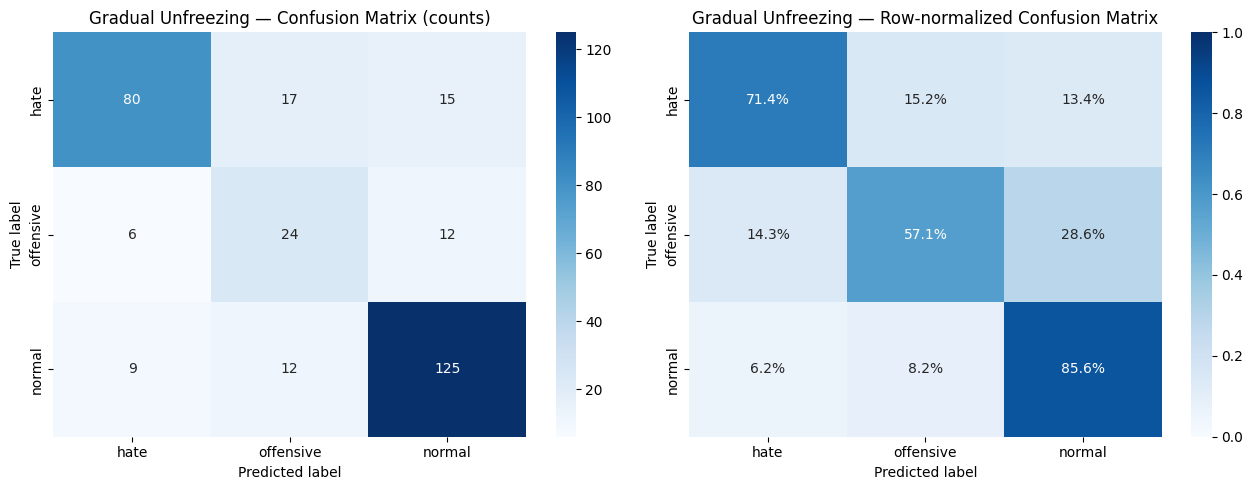

,precision,recall,f1-score,support
hate,0.842105,0.714286,0.772947,112.000000
offensive,0.452830,0.571429,0.505263,42.000000
normal,0.822368,0.856164,0.838926,146.000000
accuracy,0.763333,0.763333,0.763333,0.763333
macro avg,0.705768,0.713960,0.705712,300.000000
weighted avg,0.778001,0.763333,0.767581,300.000000


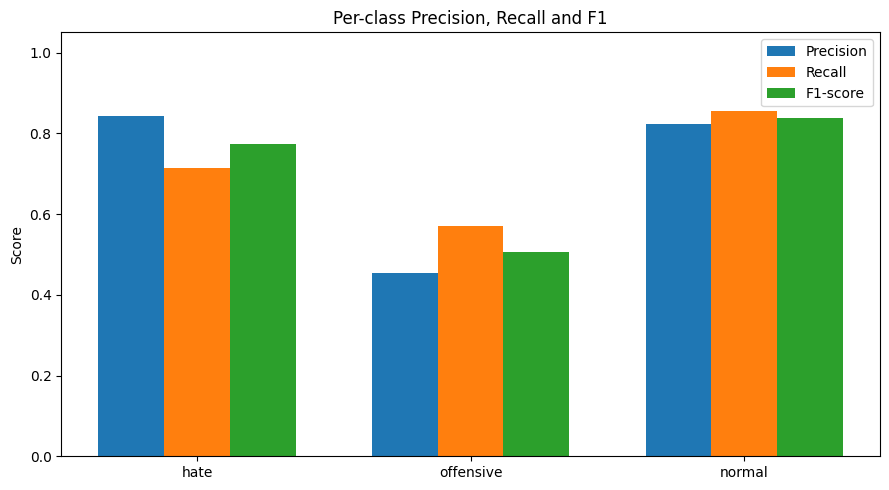

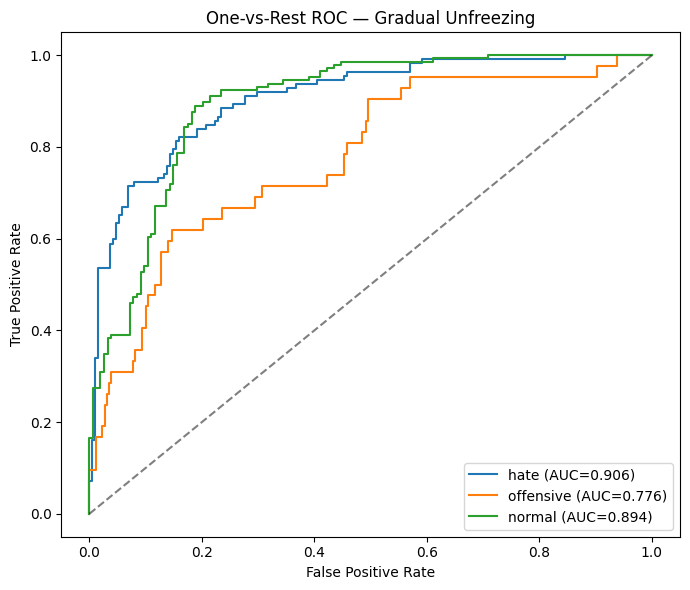

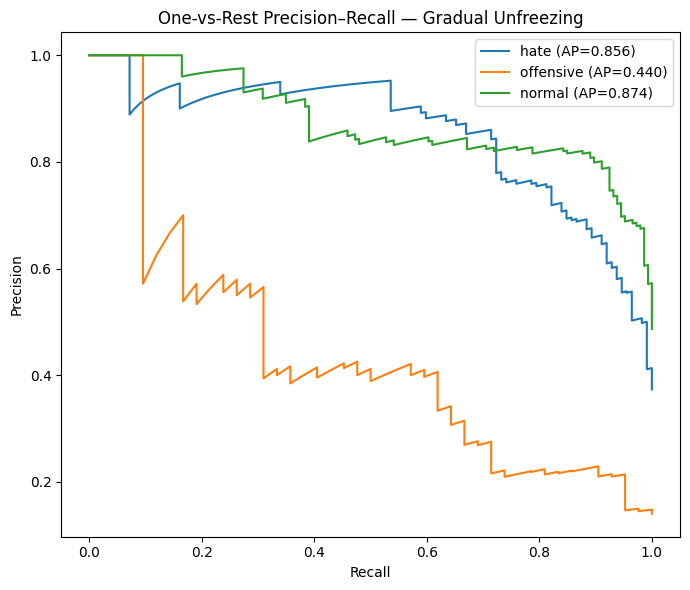

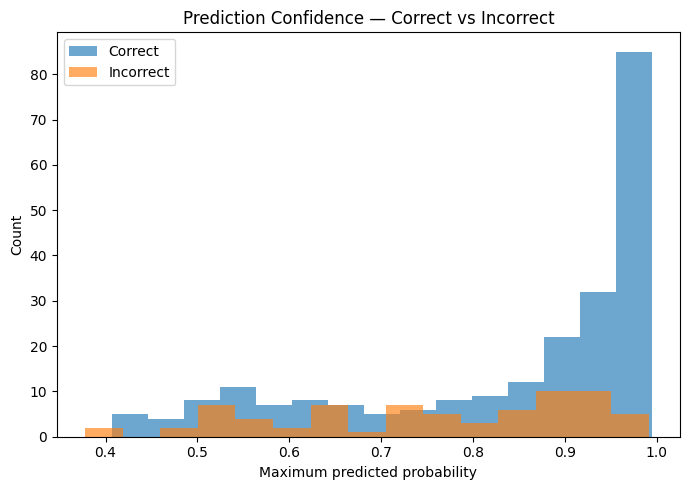

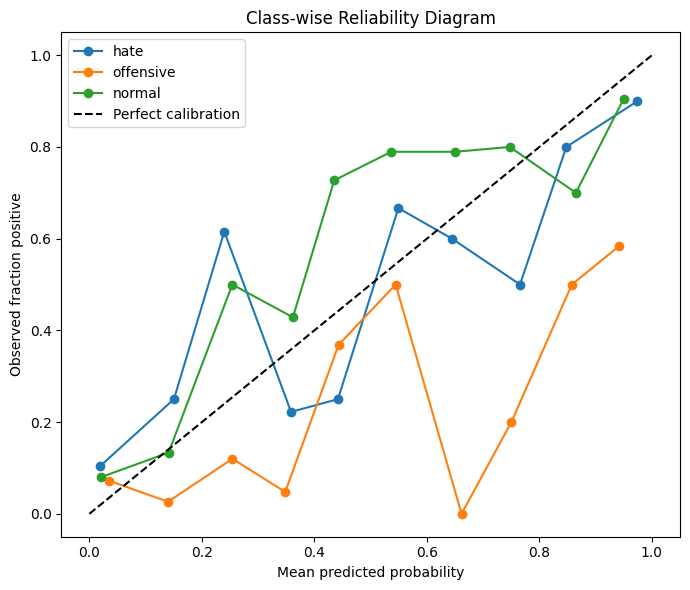

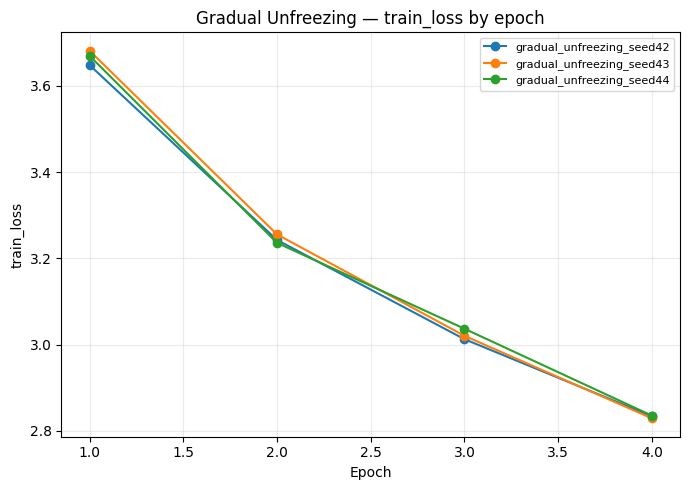

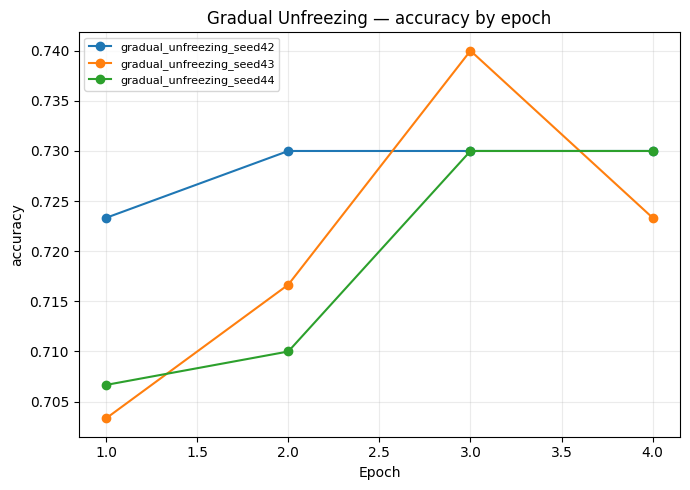

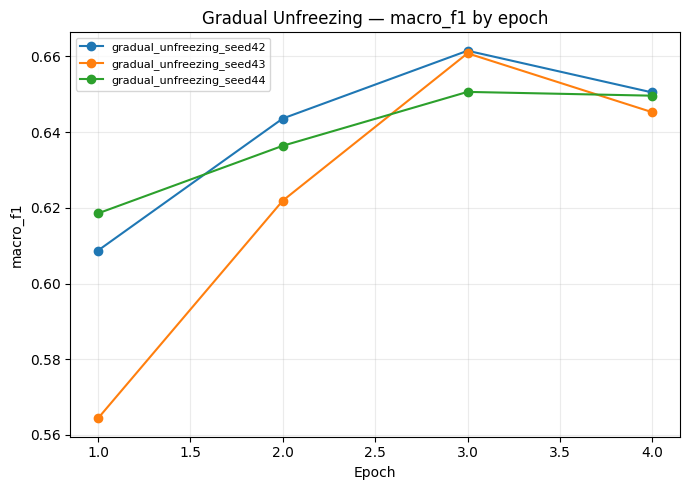

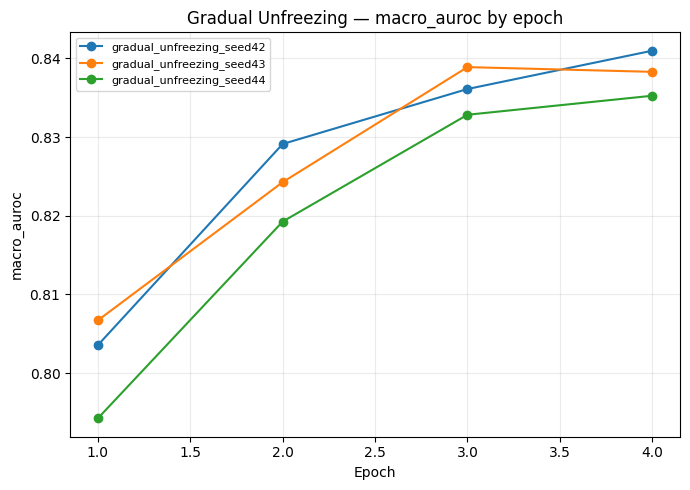

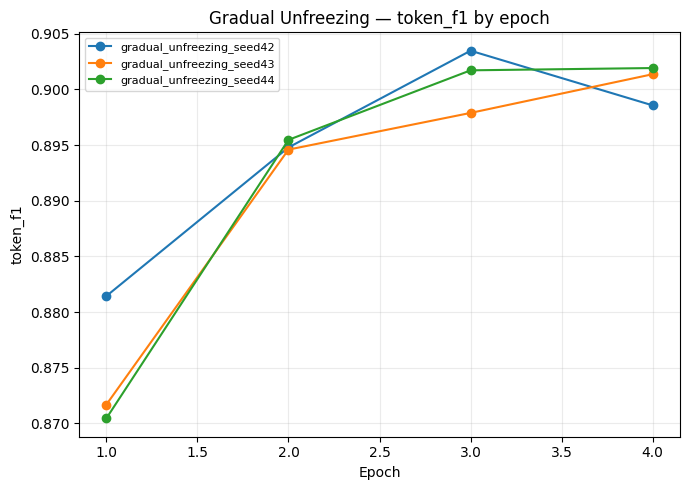

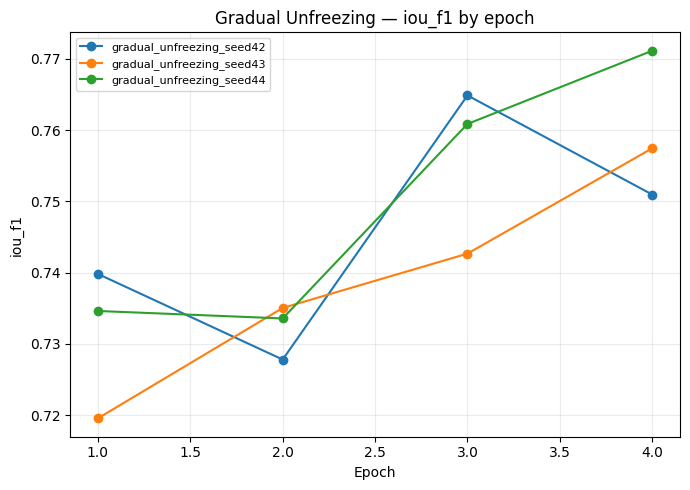

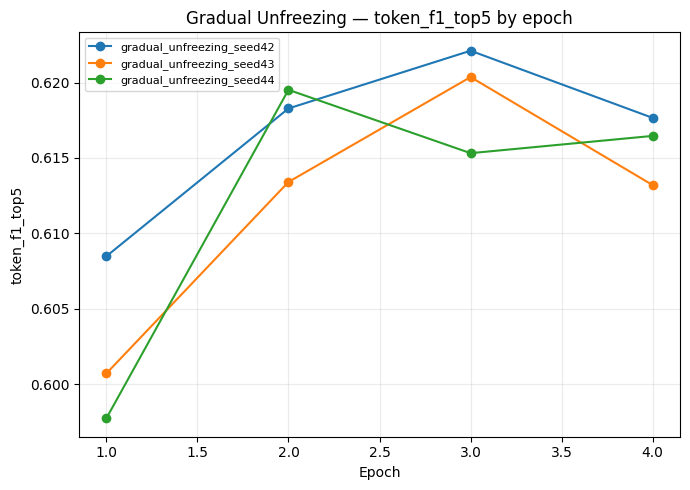

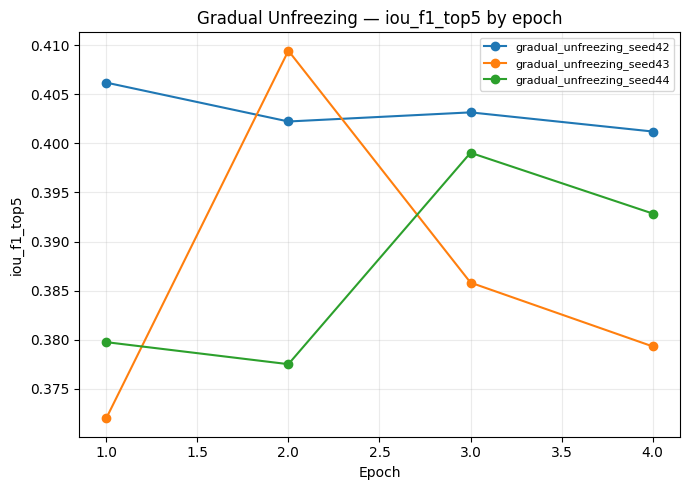

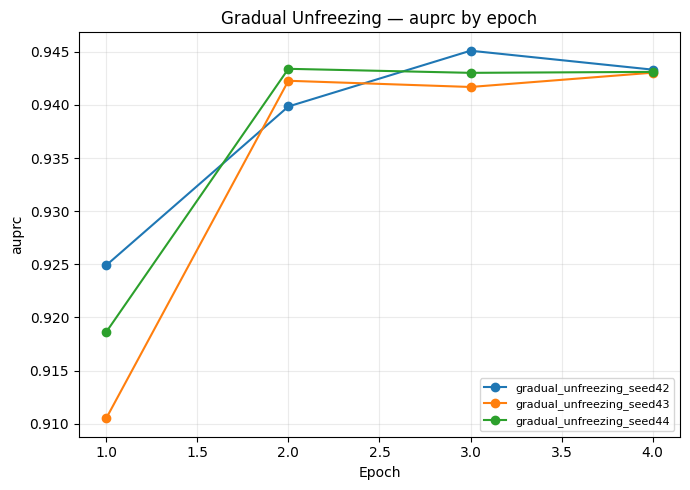

Test examples with token-level gold rationales: 176/300


,seed,token_f1,iou_f1,token_f1_top5,iou_f1_top5,auprc,comprehensiveness,sufficiency,comprehensiveness_20pct,sufficiency_20pct
0,42,0.870897,0.742443,0.622467,0.416955,0.915067,0.326397,0.195465,0.309129,0.236938
1,43,0.881386,0.777428,0.621283,0.415760,0.918839,0.326415,0.198674,0.304914,0.235062
2,44,0.868107,0.746605,0.616104,0.393125,0.908821,0.350668,0.243871,0.333453,0.276337


Gold rationale annotations are available. The token-F1 / IOU-F1 / AUPRC columns are evaluated against those annotations using the protocol defined in the source notebook.


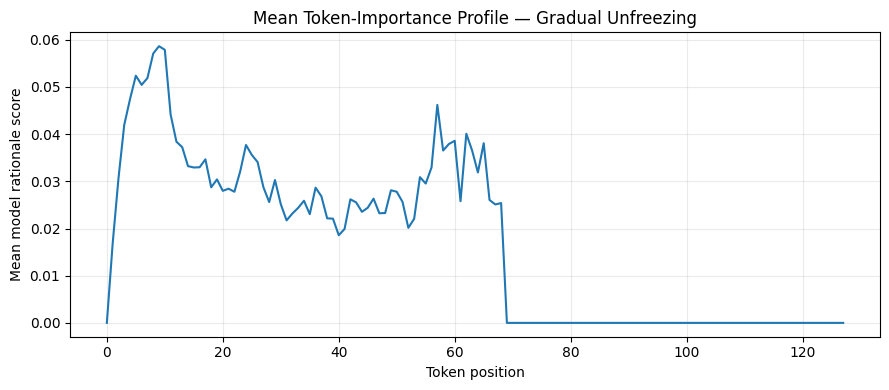

,example_index,true_label,predicted_label,confidence,top_tokens,gold_rationale_available
0,0,hate,hate,0.990656,##gger ni at this back the put of,True
1,1,hate,hate,0.983228,ki ##ke ##nat ##ll wig shi or iq,True
2,2,normal,normal,0.993571,made stuffing and arrests box violence opposit...,False
3,3,offensive,normal,0.898452,##gga ni sexual young ##in my one limits,True
4,4,offensive,offensive,0.571985,arabs goat from condom belly condom of the,True
5,5,normal,normal,0.569024,##man china satan ##ist ##ic criminals hs satan,False
6,6,hate,offensive,0.906720,fa ##ot ##gg struggle a pick like,True
7,7,normal,normal,0.745013,illegal immigrants sanctuary cities placing in...,False
8,8,normal,normal,0.842645,##m mo ##sle ##s skin truck until melt,True
9,9,hate,normal,0.956371,pak ##i ##sle mo ##m perfect spoke one,True


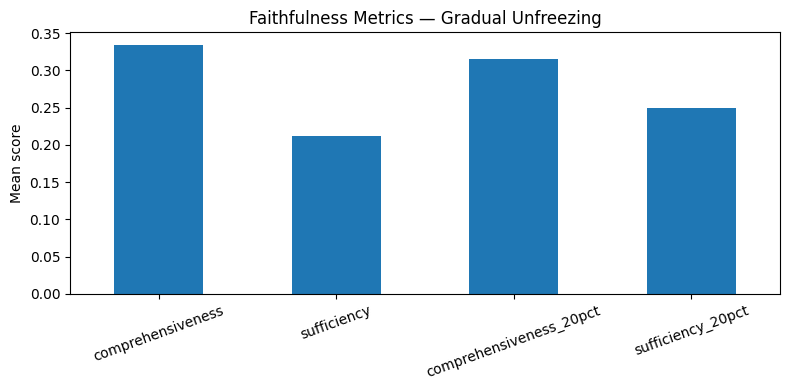

Saved Gradual Unfreezing figures and tables to: /content/ragf_bert/gradual_unfreezing_figures
Files: ['calibration_curves.png', 'classification_report_per_class.csv', 'confidence_distribution.png', 'confusion_matrices.png', 'confusion_matrix_counts.csv', 'faithfulness_metrics.png', 'gradual_unfreezing_epoch_history.csv', 'gradual_unfreezing_mean_std_metrics.csv', 'gradual_unfreezing_per_seed_metrics.csv', 'learning_curve_accuracy.png', 'learning_curve_auprc.png', 'learning_curve_iou_f1.png', 'learning_curve_iou_f1_top5.png', 'learning_curve_macro_auroc.png', 'learning_curve_macro_f1.png', 'learning_curve_token_f1.png', 'learning_curve_token_f1_top5.png', 'learning_curve_train_loss.png', 'mean_token_importance_profile.png', 'per_class_prf1.png', 'precision_recall_curves.png', 'qualitative_top_token_explanations.csv', 'roc_curves.png']


In [36]:
# ================= GRADUAL UNFREEZING: PAPER FIGURES & METRICS =================
import os, glob, json, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import (
    confusion_matrix, classification_report, precision_recall_fscore_support,
    roc_curve, auc, precision_recall_curve, average_precision_score,
    brier_score_loss
)
from sklearn.preprocessing import label_binarize
from sklearn.calibration import calibration_curve

METHOD = "+ gradual unfreezing"
LABELS = [ID2LABEL[i] for i in range(3)]
FIG_DIR = os.path.join(OUTPUT_DIR, "gradual_unfreezing_figures")
os.makedirs(FIG_DIR, exist_ok=True)

if "results_df" not in globals() or results_df.empty:
    raise RuntimeError("Run the experiment runner first; results_df is missing or empty.")
if METHOD not in set(results_df["method"]):
    available = sorted(results_df["method"].dropna().unique().tolist())
    raise RuntimeError(
        f"{METHOD!r} is not in results_df. Available methods: {available}. "
        "Re-run the experiment cell after applying the gradual-unfreezing runner update."
    )
if "trained_models" not in globals() or METHOD not in trained_models:
    raise RuntimeError("Gradual-unfreezing test predictions are missing from trained_models.")

gradual_rows = results_df[results_df.method == METHOD].copy().sort_values("seed")
display(gradual_rows)

# 1) Per-seed results and mean +/- SD for every available classification/explainability metric.
metric_candidates = [
    "accuracy", "macro_f1", "macro_auroc",
    "token_f1", "iou_f1", "token_f1_top5", "iou_f1_top5", "auprc",
    "comprehensiveness", "sufficiency",
    "comprehensiveness_20pct", "sufficiency_20pct"
]
available_metrics = [m for m in metric_candidates if m in gradual_rows.columns]
summary_rows = []
for metric in available_metrics:
    vals = pd.to_numeric(gradual_rows[metric], errors="coerce").dropna()
    summary_rows.append({
        "metric": metric,
        "mean": vals.mean() if len(vals) else np.nan,
        "std": vals.std(ddof=1) if len(vals) > 1 else np.nan,
        "n_valid_seeds": int(len(vals))
    })
gradual_summary = pd.DataFrame(summary_rows)
display(gradual_summary.style.format({"mean":"{:.4f}", "std":"{:.4f}"}))
gradual_rows.to_csv(os.path.join(FIG_DIR, "gradual_unfreezing_per_seed_metrics.csv"), index=False)
gradual_summary.to_csv(os.path.join(FIG_DIR, "gradual_unfreezing_mean_std_metrics.csv"), index=False)

# 2) Use the first recorded seed's held-out predictions for example-level plots.
# Report mean +/- SD across seeds above; do not treat this single-seed matrix as an average.
_, outputs, _ = trained_models[METHOD]
y_true, y_prob, y_pred, rationale_pred, rationale_gold, rationale_available, attention_masks = outputs
y_true = np.asarray(y_true).astype(int)
y_prob = np.asarray(y_prob)
y_pred = np.asarray(y_pred).astype(int)
rationale_pred = np.asarray(rationale_pred)
rationale_gold = np.asarray(rationale_gold)
rationale_available = np.asarray(rationale_available)
attention_masks = np.asarray(attention_masks)

# Confusion matrices: counts and row-normalized percentages.
cm = confusion_matrix(y_true, y_pred, labels=[0,1,2])
cm_norm = confusion_matrix(y_true, y_pred, labels=[0,1,2], normalize="true")
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=LABELS, yticklabels=LABELS, ax=axes[0])
axes[0].set_title("Gradual Unfreezing — Confusion Matrix (counts)")
axes[0].set_xlabel("Predicted label"); axes[0].set_ylabel("True label")
sns.heatmap(cm_norm, annot=True, fmt=".1%", cmap="Blues", vmin=0, vmax=1,
            xticklabels=LABELS, yticklabels=LABELS, ax=axes[1])
axes[1].set_title("Gradual Unfreezing — Row-normalized Confusion Matrix")
axes[1].set_xlabel("Predicted label"); axes[1].set_ylabel("True label")
plt.tight_layout(); plt.savefig(os.path.join(FIG_DIR, "confusion_matrices.png"), dpi=300, bbox_inches="tight"); plt.show()
pd.DataFrame(cm, index=[f"true_{x}" for x in LABELS], columns=[f"pred_{x}" for x in LABELS]).to_csv(
    os.path.join(FIG_DIR, "confusion_matrix_counts.csv")
)

# 3) Per-class precision, recall, F1 and support.
report_dict = classification_report(y_true, y_pred, labels=[0,1,2], target_names=LABELS,
                                    output_dict=True, zero_division=0)
class_report = pd.DataFrame(report_dict).T
display(class_report)
class_report.to_csv(os.path.join(FIG_DIR, "classification_report_per_class.csv"))
pr, rc, f1, support = precision_recall_fscore_support(y_true, y_pred, labels=[0,1,2], zero_division=0)
fig, ax = plt.subplots(figsize=(9,5))
x = np.arange(3); width = 0.24
ax.bar(x-width, pr, width, label="Precision")
ax.bar(x, rc, width, label="Recall")
ax.bar(x+width, f1, width, label="F1-score")
ax.set_xticks(x, LABELS); ax.set_ylim(0,1.05); ax.set_ylabel("Score")
ax.set_title("Per-class Precision, Recall and F1"); ax.legend()
plt.tight_layout(); plt.savefig(os.path.join(FIG_DIR, "per_class_prf1.png"), dpi=300, bbox_inches="tight"); plt.show()

# 4) Multiclass one-vs-rest ROC and precision-recall curves.
y_bin = label_binarize(y_true, classes=[0,1,2])
fig, ax = plt.subplots(figsize=(7,6))
for k, name in enumerate(LABELS):
    fpr, tpr, _ = roc_curve(y_bin[:,k], y_prob[:,k])
    ax.plot(fpr, tpr, label=f"{name} (AUC={auc(fpr,tpr):.3f})")
ax.plot([0,1],[0,1],"k--",alpha=.5); ax.set(xlabel="False Positive Rate", ylabel="True Positive Rate",
    title="One-vs-Rest ROC — Gradual Unfreezing"); ax.legend()
plt.tight_layout(); plt.savefig(os.path.join(FIG_DIR, "roc_curves.png"), dpi=300, bbox_inches="tight"); plt.show()

fig, ax = plt.subplots(figsize=(7,6))
for k, name in enumerate(LABELS):
    precision, recall, _ = precision_recall_curve(y_bin[:,k], y_prob[:,k])
    ap = average_precision_score(y_bin[:,k], y_prob[:,k])
    ax.plot(recall, precision, label=f"{name} (AP={ap:.3f})")
ax.set(xlabel="Recall", ylabel="Precision", title="One-vs-Rest Precision–Recall — Gradual Unfreezing")
ax.legend()
plt.tight_layout(); plt.savefig(os.path.join(FIG_DIR, "precision_recall_curves.png"), dpi=300, bbox_inches="tight"); plt.show()

# 5) Confidence and calibration diagnostics.
confidence = y_prob.max(axis=1)
correct = (y_pred == y_true)
fig, ax = plt.subplots(figsize=(7,5))
ax.hist(confidence[correct], bins=15, alpha=.65, label="Correct")
ax.hist(confidence[~correct], bins=15, alpha=.65, label="Incorrect")
ax.set(xlabel="Maximum predicted probability", ylabel="Count",
       title="Prediction Confidence — Correct vs Incorrect"); ax.legend()
plt.tight_layout(); plt.savefig(os.path.join(FIG_DIR, "confidence_distribution.png"), dpi=300, bbox_inches="tight"); plt.show()

fig, ax = plt.subplots(figsize=(7,6))
for k, name in enumerate(LABELS):
    if len(np.unique(y_bin[:,k])) < 2: continue
    frac_pos, mean_pred = calibration_curve(y_bin[:,k], y_prob[:,k], n_bins=10, strategy="uniform")
    ax.plot(mean_pred, frac_pos, marker="o", label=name)
ax.plot([0,1],[0,1],"k--",label="Perfect calibration")
ax.set(xlabel="Mean predicted probability", ylabel="Observed fraction positive",
       title="Class-wise Reliability Diagram"); ax.legend()
plt.tight_layout(); plt.savefig(os.path.join(FIG_DIR, "calibration_curves.png"), dpi=300, bbox_inches="tight"); plt.show()

# 6) Learning curves from the saved per-epoch histories (one line per seed).
history_files = sorted(glob.glob(os.path.join(OUTPUT_DIR, "*gradual_unfreezing*seed*_history.csv")))
if not history_files:
    history_files = sorted(glob.glob(os.path.join(OUTPUT_DIR, "*gradual*unfreezing*history.csv")))
if history_files:
    histories = []
    for path in history_files:
        h = pd.read_csv(path)
        h["run_file"] = os.path.basename(path)
        histories.append(h)
    hist_all = pd.concat(histories, ignore_index=True)
    hist_all.to_csv(os.path.join(FIG_DIR, "gradual_unfreezing_epoch_history.csv"), index=False)
    plot_metrics = [m for m in ["train_loss", "accuracy", "macro_f1", "macro_auroc",
                                "token_f1", "iou_f1", "token_f1_top5", "iou_f1_top5", "auprc"]
                    if m in hist_all.columns]
    for metric in plot_metrics:
        fig, ax = plt.subplots(figsize=(7,5))
        for run_file, group in hist_all.groupby("run_file"):
            ax.plot(group["epoch"], group[metric], marker="o", label=run_file.replace("_history.csv",""))
        ax.set(xlabel="Epoch", ylabel=metric, title=f"Gradual Unfreezing — {metric} by epoch")
        ax.legend(fontsize=8); ax.grid(alpha=.25)
        plt.tight_layout(); plt.savefig(os.path.join(FIG_DIR, f"learning_curve_{metric}.png"), dpi=300, bbox_inches="tight"); plt.show()
else:
    print("No gradual-unfreezing history CSV found. Learning-curve plots will appear after the training runner has completed.")

# 7) Explainability: gold-rationale metrics only when genuine annotations exist.
gold_count = int(np.sum(rationale_available > 0.5))
print(f"Test examples with token-level gold rationales: {gold_count}/{len(y_true)}")
explainability_cols = [m for m in ["token_f1","iou_f1","token_f1_top5","iou_f1_top5","auprc",
                                   "comprehensiveness","sufficiency",
                                   "comprehensiveness_20pct","sufficiency_20pct"] if m in gradual_rows.columns]
display(gradual_rows[["seed"] + explainability_cols])
if gold_count == 0:
    print("No gold token rationales in the test split: Token F1, IOU-F1 and rationale AUPRC are not valid "
          "plausibility metrics here. The model's token scores below are qualitative only.")
else:
    print("Gold rationale annotations are available. The token-F1 / IOU-F1 / AUPRC columns are evaluated "
          "against those annotations using the protocol defined in the source notebook.")

# Mean token-score profile by token position (special tokens excluded).
valid_mask = attention_masks.astype(bool)
for i in range(len(valid_mask)):
    valid_idx = np.where(valid_mask[i])[0]
    if len(valid_idx) >= 2:
        valid_mask[i, valid_idx[0]] = False
        valid_mask[i, valid_idx[-1]] = False
score_sums = np.where(valid_mask, rationale_pred, 0).sum(axis=0)
score_counts = valid_mask.sum(axis=0)
mean_token_score = score_sums / np.maximum(score_counts, 1)
fig, ax = plt.subplots(figsize=(9,4))
ax.plot(np.arange(len(mean_token_score)), mean_token_score)
ax.set(xlabel="Token position", ylabel="Mean model rationale score",
       title="Mean Token-Importance Profile — Gradual Unfreezing")
ax.grid(alpha=.25); plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "mean_token_importance_profile.png"), dpi=300, bbox_inches="tight"); plt.show()

# Save qualitative top-token examples. Uses tokenizer/model token scores already returned by evaluation.
def extract_top_token_examples(n_examples=12, top_k=8):
    rows = []
    for i in range(min(n_examples, len(y_true))):
        # Reconstruct tokens from the test dataset item when available.
        item = test_ds[i]
        ids = item["input_ids"].detach().cpu().numpy()
        mask = item["attention_mask"].detach().cpu().numpy().astype(bool)
        toks = tokenizer.convert_ids_to_tokens(ids.tolist())
        valid = mask.copy()
        valid_ids = np.where(valid)[0]
        if len(valid_ids) >= 2:
            valid[valid_ids[0]] = False; valid[valid_ids[-1]] = False
        ranked = [j for j in np.argsort(rationale_pred[i])[::-1] if valid[j]][:top_k]
        rows.append({
            "example_index": i,
            "true_label": ID2LABEL[int(y_true[i])],
            "predicted_label": ID2LABEL[int(y_pred[i])],
            "confidence": float(np.max(y_prob[i])),
            "top_tokens": " ".join(toks[j] for j in ranked),
            "gold_rationale_available": bool(rationale_available[i] > .5)
        })
    return pd.DataFrame(rows)

top_token_df = extract_top_token_examples()
display(top_token_df)
top_token_df.to_csv(os.path.join(FIG_DIR, "qualitative_top_token_explanations.csv"), index=False)

# 8) Faithfulness metrics already calculated for each run in the experiment runner.
faith_cols = [m for m in ["comprehensiveness","sufficiency","comprehensiveness_20pct","sufficiency_20pct"] if m in gradual_rows]
if faith_cols:
    faith_mean = gradual_rows[faith_cols].mean(numeric_only=True)
    fig, ax = plt.subplots(figsize=(8,4))
    faith_mean.plot(kind="bar", ax=ax)
    ax.set_ylabel("Mean score"); ax.set_title("Faithfulness Metrics — Gradual Unfreezing")
    ax.tick_params(axis="x", rotation=20)
    plt.tight_layout(); plt.savefig(os.path.join(FIG_DIR, "faithfulness_metrics.png"), dpi=300, bbox_inches="tight"); plt.show()

# 9) Export a compact paper-ready metric summary and all figures.
print("Saved Gradual Unfreezing figures and tables to:", FIG_DIR)
print("Files:", sorted(os.listdir(FIG_DIR)))
